In [1]:
# === Imports ===
import numpy as np  # Array operations
import matplotlib.pyplot as plt  # Plotting
from matplotlib.colors import LinearSegmentedColormap, to_rgba_array # For the color scheme
import matplotlib.gridspec as gridspec
import pandas as pd  # Data handling
import pyp2options  # Custom library --> Calibrations
from astropy.coordinates import SkyCoord  # Astronomical coordinate handling
import astropy.units as u  # Physical units
import scipy.optimize as spopt  # Optimization algorithms
import sys
#from matplotlib.backends.backend_pdf import PdfPages  # Save multiple figures into a PDF

In [2]:
# === Color Scheme ===
def discretemap(name, clrs):
    """Create a discrete colormap."""
    return LinearSegmentedColormap.from_list(name, clrs, N=len(clrs))

class TOLcmaps:
    """
    Class defining only the 'nightfall_discrete' colormap.
    """
    def __init__(self):
        self.cmap = None
        self.cname = None
        self.namelist = ('nightfall_discrete',)

    def __nightfall_discrete(self):
        """
        Define colormap 'nightfall_discrete'.
        """
        clrs = ['#125A56', '#238F9D', '#60BCE9', '#C6DBED', '#ECEADA',
                '#F9D576', '#FD9A44', '#E94C1F', '#A01813']
        self.cmap = discretemap(self.cname, clrs)
        self.cmap.set_bad('#FFFFFF')

    def get(self, cname='nightfall_discrete', lut=None):
        """
        Return the requested colormap.
        """
        self.cname = cname
        if cname == 'nightfall_discrete':
            self.__nightfall_discrete()
        else:
            # fallback in case colormap is not defined
            print(f'*** Warning: requested colormap "{cname}" not defined, '
                  f'using "nightfall_discrete".')
            self.__nightfall_discrete()
        return self.cmap

def tol_cmap(colormap=None, lut=None):
    """
    Continuous and discrete color sets for ordered data.

    Return a matplotlib colormap.
    """
    obj = TOLcmaps()
    if colormap is None:
        return obj.namelist
    if colormap not in obj.namelist:
        print('*** Warning: requested colormap not defined,',
              'known colormaps are {}.'.format(obj.namelist),
              'Using nightfall_discrete.')
        colormap = 'nightfall_discrete'
    return obj.get(colormap, lut)

In [3]:
# === Defined Parameters ===
field_name = 'MISHAPS_F1_DITH0'  # Field identifier
chip_id = 'N10'  # Chip identifier
magnitude_band = 'r'  # Band used for magnitude measurement
color_band_1 = 'r'  # First band for color (e.g. r-z)
color_band_2 = 'z'  # Second band for color
field_chip_label = f"{field_name}_{chip_id}"  # Combined label for file references

In [4]:
# CMD (Color-Magnitude Diagram) Parameters
default_color_cut = 1.06
magnitude_cut = 17.3
color_range_min = 0.0
color_range_max = 2.0
msto_shift_value = 3.5  # Main Sequence Turn-Off shift

In [5]:
# Adjust defaults for specific color combinations
if color_band_2 == "z" and color_band_1 == "r":
    # default_color_cut = 0.46
    default_color_cut = 0.6
    color_range_max = 1.0
    msto_shift_value = 3.0

In [6]:
# Enable interactive plots if enough command-line arguments are provided
interactive_mode = False
if len(sys.argv) >= 6:
    interactive_mode = True

# Optionally override color and magnitude cuts
if len(sys.argv) >= 7:
    default_color_cut = float(sys.argv[6])
    print("Color cut set to:", default_color_cut)

if len(sys.argv) >= 8:
    magnitude_cut = float(sys.argv[7])
    print("Magnitude cut set to:", magnitude_cut)

print("Using magnitude and color bands:", magnitude_band, color_band_1, color_band_2)

Using magnitude and color bands: r r z


In [7]:
# Optional positional filtering via RA/Dec limits
ra_min, ra_max = -1, -1
dec_min, dec_max = -1, -1
apply_position_cut = False

if len(sys.argv) >= 9:
    ra_min = float(sys.argv[8])
    ra_max = float(sys.argv[9])
    dec_min = float(sys.argv[10])
    dec_max = float(sys.argv[11])
    apply_position_cut = True

In [10]:
# === Load Configuration from Options File ===
options = pyp2options.pip2options('/home/bernthold.17/SURP2025/fit_models_N10/')

/home/bernthold.17/SURP2025/fit_models_N10/pyp2options.py:12: ParserWarning: Skipping line 65: expected 2 fields, saw 5
Skipping line 68: expected 2 fields, saw 5
Skipping line 71: expected 2 fields, saw 5
Skipping line 74: expected 2 fields, saw 5
Skipping line 80: expected 2 fields, saw 5
Skipping line 83: expected 2 fields, saw 5

  df = pd.read_csv(pipedir + '/pip2options.sh',sep='=',header=None,comment="#",on_bad_lines=on_bad_lines)


In [11]:
# Column indices for quality flags
qflag_mag = options['cmdq-' + magnitude_band] - 1
qflag_c1 = options['cmdq-' + color_band_1] - 1
qflag_c2 = options['cmdq-' + color_band_2] - 1

# Column indices for magnitudes
mag_col_index = options['cmdm-' + magnitude_band] - 1
c1_col_index = options['cmdm-' + color_band_1] - 1
c2_col_index = options['cmdm-' + color_band_2] - 1

# Column indices for position
ra_col_index = 1
dec_col_index = 2

In [12]:
# Reference directory for outputs
reference_directory = '/home/bernthold.17/SURP2025/fit_models/'

In [13]:
# Image grid dimensions
grid_cols = 4
grid_rows = 8
subimage_size = 2048.0 / grid_cols

In [14]:
# === Red Clump Color Reference Function ===
# The numbers come from the Nataf papers --> Look them up
# l - galactic longitude, b - galactic latitude, our view of a star relative to the galactic center (0, 0)
def red_clump_color(l, b):
    """Returns the expected intrinsic color of the red clump stars given Galactic coordinates."""
    I_0 = 14.3955 - 0.0239 * l + 0.0122 * np.abs(b) # Dereddened I mag of the red clump (rc)
    I_mag = np.array([I_0, I_0 + 0.737, I_0 - 1.07]) # The I mag of the rc, red giant branch (rgbb),
                                                        # and asymptotic giant branch (agbb)
    dis_mod = I_mag - 14.3955 + 5.0 * np.log10(8178.0) - 5.0 # Distance modulus of bar peak density
    distance = 10**(0.2 * (dis_mod + 5.0)) # Distance from ... --> Figure it out
    V_mag = 1.060 + I_mag
    
    # Use the relations between U, B, V, R, I mags and Sloan Digital Sky Survey (SDSS) u, g, r, i, z mags to get 
     # the g, r, i, z mags
    g_sdss = V_mag + 0.553 # g sdss filter (mag)
    r_sdss = V_mag - 0.327 # r sdss  filter (mag)
    i_sdss = V_mag - 0.600 # i sdss filter (mag)
    
    gmi_sdss = g_sdss - i_sdss # (g-i) sdss color
    
    rgbb_r_sdss = 1.060 + I_mag + 0.737 - 0.327 # r sdss filter of the red giant branch
    agbb_r_sdss = 1.060 + I_mag - 1.070 - 0.327 # r sdss filter of the asymptotic giant branch
    rgbb_gmi_sdss = 0.553 + 0.600 - 0.060 # (g-i) sdss color of the red giant branch
    agbb_gmi_sdss = 0.553 + 0.600 + 0.200 # (g-i) sdss color of the asymptotic giant branch
    
    print("r sdss:", r_sdss, rgbb_r_sdss, agbb_r_sdss)
    print("gmi sdss:", gmi_sdss, rgbb_gmi_sdss, agbb_gmi_sdss)
    
    # Transforms from SDSS to PanSTARRS
    for i in np.arange(0, 10):
        gpmgs = -0.01808 - 0.13595 * gmi_sdss + 0.01941 * gmi_sdss**2 - 0.00183 * gmi_sdss**3
        rpmrs = -0.01836 - 0.03577 * gmi_sdss + 0.02612 * gmi_sdss**2 - 0.00558 * gmi_sdss**3
        ipmis = 0.01170 - 0.00400 * gmi_sdss + 0.00066 * gmi_sdss**2 - 0.00058 * gmi_sdss**3
        g_ps1 = g_sdss + gpmgs #g panstarrs
        r_ps1 = r_sdss + rpmrs #r panstarrs
        i_ps1 = i_sdss + ipmis #i panstarrs
        gmi_ps1 = g_ps1 - i_ps1 #gmi panstarrs
        rmi_ps1 = r_ps1 - i_ps1 #rmi panstarrs
        imz_ps1 = 0.234625 + 0.211715 * (gmi_ps1 - 1.25) #i-z panstarrs
        rmz_ps1 = rmi_ps1 + imz_ps1 #r-z panstarrs
        z_ps1 = r_ps1 - rmz_ps1 #z panstarrs
        
        print()

    # Return the PanSTARRS magnitudes, distance, and distance modulus as a dictionary
    ret = {"clump-g":g_ps1[0], "clump-r":r_ps1[0], "clump-i":i_ps1[0], "clump-z":z_ps1[0],
           "rgbb-g":g_ps1[1], "rgbb-r":r_ps1[1], "rgbb-i":i_ps1[1], "rgbb-z":z_ps1[1],
           "agbb-g":g_ps1[2], "agbb-r":r_ps1[2], "agbb-i":i_ps1[2], "agbb-z":z_ps1[2],
           "distance":distance[0], "distance_modulus":dis_mod[0]}

    #return zp[0],rmz[0],rp[1]-rp[0],rp[2]-rp[0],gmi[0],dmod[0],d[0]
    #return ip[0],gmi[0],ip[1]-ip[0],ip[2]-ip[0],gmi[0],dmod[0],d[0]

    return ret

In [15]:
# === Load and Filter Photometric Catalog ===
catalog_path = "/home/bernthold.17/SURP2025/Data_Files/" + field_chip_label + ".cmd.calibrate_ps"
print(f"Reading catalog from: {catalog_path}")

Reading catalog from: /home/bernthold.17/SURP2025/Data_Files/MISHAPS_F1_DITH0_N10.cmd.calibrate_ps


In [16]:
# Load the photometric catalog with mixed data types
try:
    photometric_catalog_df = pd.read_csv(catalog_path, delim_whitespace=True, comment='#', header=None)
    photometric_catalog = photometric_catalog_df.values  # convert to NumPy array for compatibility
except Exception as error:
    print(f"Error loading catalog: {error}")
    sys.exit(1)
#print(photometric_catalog_df.values.dtype)
#print(photometric_catalog)

/tmp/slurmtmp.8985486/ipykernel_2816408/2368393508.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  photometric_catalog_df = pd.read_csv(catalog_path, delim_whitespace=True, comment='#', header=None)


In [17]:
# Apply magnitude quality flag filters
valid_quality = (
    #(photometric_catalog[:, qflag_mag] == 1) &
    (photometric_catalog[:, qflag_c1] == 1) &
    (photometric_catalog[:, qflag_c2] == 1)
)
filtered_catalog = photometric_catalog[valid_quality]
print(f"Stars passing quality cuts: {len(filtered_catalog)}")

Stars passing quality cuts: 34630


In [18]:
# Optional position-based filtering using RA/Dec limits
if apply_position_cut:
    ra_values = filtered_catalog[:, ra_col_index]
    dec_values = filtered_catalog[:, dec_col_index]
    within_bounds = (
        (ra_values > ra_min) & (ra_values < ra_max) &
        (dec_values > dec_min) & (dec_values < dec_max)
    )
    filtered_catalog = filtered_catalog[within_bounds]

print(f"Stars within RA/Dec bounds: {len(filtered_catalog)}")

Stars within RA/Dec bounds: 34630


In [19]:
# Get the mean RA and Dec
ra = np.nanmean(filtered_catalog[:, ra_col_index])
dec = np.nanmean(filtered_catalog[:, dec_col_index])

# Get the l and b coordinates
coords = SkyCoord(ra,dec,frame = 'icrs',unit = u.deg)
l = coords.galactic.l.value
b = coords.galactic.b.value
print("Galactic Coordinates:",l,b)
global rgbbmag0
global agbbmag0

# Estimate initial red clump guess
red_clump = red_clump_color(l, b)

clumpmag0_r = red_clump["clump-" + magnitude_band]
clumpmag0_z = red_clump["clump-" + color_band_2]

rgbbmag0_r = red_clump["rgbb-" + magnitude_band]
rgbbmag0_z = red_clump["rgbb-" + color_band_2]

agbbmag0_r = red_clump["agbb-" + magnitude_band]
agbbmag0_z = red_clump["agbb-" + color_band_2]

print(clumpmag0_r, clumpmag0_z)
print(rgbbmag0_r, rgbbmag0_z)
print(agbbmag0_r, agbbmag0_z)

Galactic Coordinates: 4.835380350738254 -7.903082849743301
r sdss: [15.10935202 15.84635202 14.03935202] [15.84635202 16.58335202 14.77635202] [14.03935202 14.77635202 12.96935202]
gmi sdss: [1.153 1.153 1.153] 1.093 1.353










15.075920301604565 14.66298295128401
15.812920301604565 15.39998295128401
14.005920301604565 13.592982951284009


In [20]:
# === Red Clump Model (Quadratic + Gaussian) for the r-band ===
def rcmodel_r(x, amplitude, slope, magnitude_rc, number_rc, sigma_rc):
    x = np.float64(x)
    A = amplitude*np.exp(slope*(x - magnitude_rc))
    B = number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-magnitude_rc)**2/sigma_rc**2)
    C = 0.201*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+rgbbmag0_r))**2/sigma_rc**2)
    D = 0.028*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+agbbmag0_r))**2/sigma_rc**2)
    return A + B + C + D     

In [21]:
# === Red Clump Model (Quadratic + Gaussian) for the z-band ===
def rcmodel_z(x, amplitude, slope, magnitude_rc, number_rc, sigma_rc):
    x = np.float64(x)
    A = amplitude*np.exp(slope*(x - magnitude_rc))
    B = number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-magnitude_rc)**2/sigma_rc**2)
    C = 0.201*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+rgbbmag0_z))**2/sigma_rc**2)
    D = 0.028*number_rc/(np.sqrt(2*np.pi*sigma_rc**2))*np.exp(-0.5*(x-(magnitude_rc+agbbmag0_z))**2/sigma_rc**2)
    return A + B + C + D  

In [22]:
# === Red Clump Gaussian ===
def cgauss(x, amplitude, mean, sigma):
    x = np.float64(x)
    return amplitude/(np.sqrt(2*np.pi*sigma**2))*np.exp(-0.5*(x-mean)**2/sigma**2)

In [23]:
# === Construct Color-Magnitude Diagram (CMD) ===
# Compute color index and magnitude
color_index = filtered_catalog[:, c1_col_index] - filtered_catalog[:, c2_col_index]
magnitude_values_r = filtered_catalog[:, mag_col_index] # r-band
magnitude_values_z = filtered_catalog[:, c2_col_index] # z-band

In [24]:
# === Giant Star Selection (r-band) ===
# Filter stars that are likely giants
# Filter for the giants
giant_candidates = filtered_catalog[(color_index > default_color_cut) & (magnitude_values_r < magnitude_cut)]

giant_colors = giant_candidates[:, c1_col_index] - giant_candidates[:, c2_col_index]
giant_magnitudes = giant_candidates[:, mag_col_index]

print(f"Selected {len(giant_candidates)} giant star candidates in the r-band")

# For the magnitude distribution fit of the whole red giant branch
# Create a histogram of magnitudes
hist_counts_giant, bin_edges_giant = np.histogram(giant_magnitudes, range = (magnitude_cut - 4.0,magnitude_cut), bins = 60, density = False) # bins the magnitudes of the giants
bin_centers_giant = 0.5 * (bin_edges_giant[0:-1] + bin_edges_giant[1:]) # calculates bin centers from the bin edges

#bin_edges_giant = np.linspace(min(giant_magnitudes), max(giant_magnitudes), 50)
#bin_centers_giant = 0.5 * (bin_edges_giant[1:] + bin_edges_giant[:-1])
#hist_counts_giant, _ = np.histogram(giant_magnitudes, bins = bin_edges_giant)

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_0 = (hist_counts_giant>0)
hist_counts_m0 = hist_counts_giant[mask_0]
bin_centers_m0 = bin_centers_giant[mask_0]

#print(type(bin_centers_m0))
#print(bin_centers_m0)

initial_guess_0 = [40.0, 0.5, 15.0, 30.0, 0.3] # Initial guess for the curve fit
initial_guess_2 = [15.0, 0.5, 15.8, 50.0, 0.4] 

par_0, cov_0 = spopt.curve_fit(rcmodel_r, bin_centers_m0, hist_counts_m0, p0 = initial_guess_2, sigma = np.sqrt(hist_counts_m0))
print(f"rcmodel Fit Results for the r-Band:\nAmplitude = {par_0[0]:.2f}\n  Slope = {par_0[1]:.2f}\n Magnitude of red clump = {par_0[2]:.2f}\n  Number of red clump stars = {par_0[3]:.2f}\n  Sigma = {par_0[4]:.2f}")

amplitude, slope, magnitude_giant, number_giant, sigma_giant = par_0

# === Giant Star Selection (z-band) ===
giant_candidates_z = filtered_catalog[(color_index > default_color_cut) & (magnitude_values_z < magnitude_cut)]

giant_colors_z = giant_candidates_z[:, c1_col_index] - giant_candidates_z[:, c2_col_index]
giant_magnitudes_z = giant_candidates_z[:, c2_col_index]

print(f"Selected {len(giant_candidates_z)} giant star candidates in the z-band")

hist_counts_giant_z, bin_edges_giant_z = np.histogram(giant_magnitudes_z, range = (magnitude_cut - 4.0,magnitude_cut), bins = 40, density = False) # bins the magnitudes of the giants
bin_centers_giant_z = 0.5 * (bin_edges_giant_z[0:-1] + bin_edges_giant_z[1:]) # calculates bin centers from the bin edges

mask_0z = (hist_counts_giant_z>0)
hist_counts_m0z = hist_counts_giant_z[mask_0z]
bin_centers_m0z = bin_centers_giant_z[mask_0z]

initial_guess_0 = [40.0, 0.5, 15.0, 30.0, 0.3] # Initial guess for the curve fit


par_0z, cov_0z = spopt.curve_fit(rcmodel_z, bin_centers_m0z, hist_counts_m0z, p0 = initial_guess_0, sigma = np.sqrt(hist_counts_m0z))
print(f"rcmodel Fit Results for the z-Band:\nAmplitude = {par_0z[0]:.2f}\n  Slope = {par_0z[1]:.2f}\n Magnitude of red clump = {par_0z[2]:.2f}\n  Number of red clump stars = {par_0z[3]:.2f}\n  Sigma = {par_0z[4]:.2f}")

amplitude, slope, magnitude_giant, number_giant, sigma_giant = par_0z

Selected 1237 giant star candidates in the r-band
rcmodel Fit Results for the r-Band:
Amplitude = 9.44
  Slope = 0.98
 Magnitude of red clump = 15.86
  Number of red clump stars = 41.99
  Sigma = 0.55
Selected 1810 giant star candidates in the z-band
rcmodel Fit Results for the z-Band:
Amplitude = 19.31
  Slope = 0.74
 Magnitude of red clump = 15.08
  Number of red clump stars = 49.08
  Sigma = 0.50


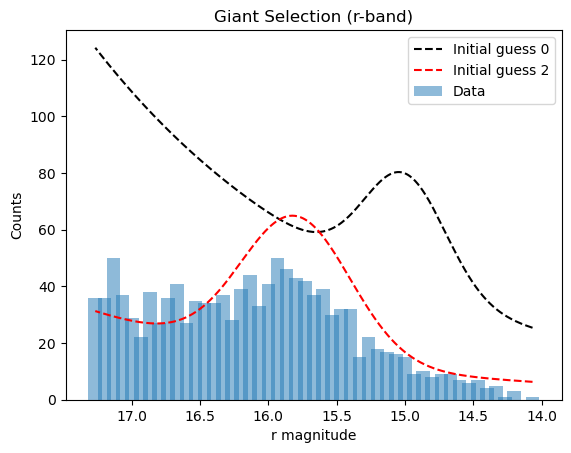

In [25]:
initial_guess_2 = [15.0, 0.5, 15.8, 50.0, 0.4] 
plt.bar(bin_centers_m0, hist_counts_m0, width=0.1, alpha=0.5, label="Data")
x_fit = np.linspace(min(bin_centers_m0), max(bin_centers_m0), 500)
y_fit_0 = rcmodel_r(x_fit, *initial_guess_0)
y_fit_2 = rcmodel_r(x_fit, *initial_guess_2)
plt.plot(x_fit, y_fit_0, 'k--', label="Initial guess 0")
plt.plot(x_fit, y_fit_2, 'r--', label="Initial guess 2")
plt.xlabel("r magnitude")
plt.ylabel("Counts")
plt.title("Giant Selection (r-band)")
plt.legend()
plt.gca().invert_xaxis()
plt.show()

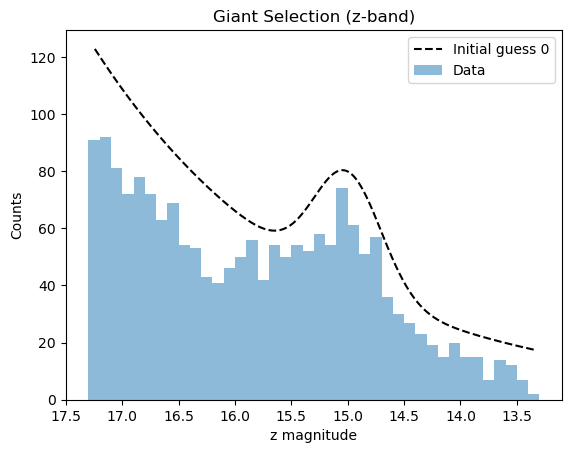

In [26]:
initial_guess_0 = [40.0, 0.5, 15.0, 30.0, 0.3] 
plt.bar(bin_centers_m0z, hist_counts_m0z, width=0.1, alpha=0.5, label="Data")
x_fit = np.linspace(min(bin_centers_m0z), max(bin_centers_m0z), 500)
y_fit_0 = rcmodel_z(x_fit, *initial_guess_0)
plt.plot(x_fit, y_fit_0, 'k--', label="Initial guess 0")
plt.xlabel("z magnitude")
plt.ylabel("Counts")
plt.title("Giant Selection (z-band)")
plt.legend()
plt.gca().invert_xaxis()
plt.show()

In [27]:
# === Red Clump Star Selection (r-band) ===
# Filter stars that are likely within the red clump
clump_candidates = giant_candidates[np.abs(giant_candidates[:, mag_col_index] - par_0[2]) < 2 * par_0[4]]

clump_colors = clump_candidates[:, c1_col_index] - clump_candidates[:, c2_col_index]
clump_magnitudes = clump_candidates[:, mag_col_index]

print(f"Selected {len(clump_candidates)} red clump candidates in the r-band")

# For the color distribution fit of stars in the red clump
# Create a histogram of colors
hist_counts_clump, bin_edges_clump = np.histogram(clump_colors, range = (default_color_cut, default_color_cut + 1.5), bins=60)
bin_centers_clump = 0.5 * (bin_edges_clump[:-1] + bin_edges_clump[1:])

# Select only the bins that aren't empty, apply that to the histogram and bin centers
mask_1 = (hist_counts_clump>0)
hist_counts_m1 = hist_counts_clump[mask_1]
bin_centers_m1 = bin_centers_clump[mask_1]

# Initial guess for Gaussian parameters: amplitude, mean, sigma
initial_guess_1 = [par_0[3] + 0.0, default_color_cut + 0.2, 0.2]
initial_guess_3 = [70.0, 0.75, 0.2]

par_1, cov_1 = spopt.curve_fit(cgauss, bin_centers_m1, hist_counts_m1, p0 = initial_guess_3, sigma=np.sqrt(hist_counts_m1))
print(f"cgauss Model Fit Results:\nAmplitude = {par_1[0]:.2f}\n  Mean = {par_1[1]:.2f}\n Sigma = {par_1[2]:.2f}")

amplitude, mean, sigma = par_1

# === Red Clump Star Selection (z-band) ===
clump_candidates_z = giant_candidates_z[np.abs(giant_candidates_z[:, c2_col_index] - par_0z[2]) < 2 * par_0z[4]]

clump_colors_z = clump_candidates_z[:, c1_col_index] - clump_candidates_z[:, c2_col_index]
clump_magnitudes_z = clump_candidates_z[:, c2_col_index]

print(f"Selected {len(clump_candidates_z)} red clump candidates in the z-band")

hist_counts_clump_z, bin_edges_clump_z = np.histogram(clump_colors_z, range = (default_color_cut, default_color_cut + 1.5), bins=60)
bin_centers_clump_z = 0.5 * (bin_edges_clump_z[:-1] + bin_edges_clump_z[1:])

mask_1z = (hist_counts_clump_z>0)
hist_counts_m1z = hist_counts_clump_z[mask_1z]
bin_centers_m1z = bin_centers_clump_z[mask_1z]

initial_guess_1 = [par_0z[3] + 0.0, default_color_cut + 0.2, 0.2]
initial_guess_4 = [65.0, 0.75, 0.2]

par_1z, cov_1z = spopt.curve_fit(cgauss, bin_centers_m1z, hist_counts_m1z, p0 = initial_guess_4, sigma=np.sqrt(hist_counts_m1z))
print(f"cgauss Model Fit Results:\nAmplitude = {par_1z[0]:.2f}\n  Mean = {par_1z[1]:.2f}\n Sigma = {par_1z[2]:.2f}")

amplitude, mean, sigma = par_1z

Selected 993 red clump candidates in the r-band
cgauss Model Fit Results:
Amplitude = 24.08
  Mean = 0.76
 Sigma = 0.09
Selected 903 red clump candidates in the z-band
cgauss Model Fit Results:
Amplitude = 21.86
  Mean = 0.76
 Sigma = 0.09


41.985298664393525 0.8 0.2


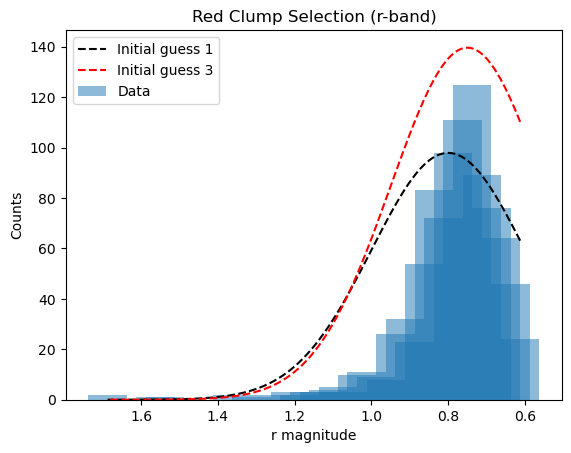

In [28]:
print(par_0[3] + 0.0, default_color_cut + 0.2, 0.2)
initial_guess_3 = [70.0, 0.75, 0.2]
plt.bar(bin_centers_m1, hist_counts_m1, width=0.1, alpha=0.5, label="Data")
x_fit = np.linspace(min(bin_centers_m1), max(bin_centers_m1), 500)
y_fit_1 = cgauss(x_fit, *initial_guess_1)
y_fit_3 = cgauss(x_fit, *initial_guess_3)
plt.plot(x_fit, y_fit_1, 'k--', label="Initial guess 1")
plt.plot(x_fit, y_fit_3, 'r--', label="Initial guess 3")
plt.xlabel("r magnitude")
plt.ylabel("Counts")
plt.title("Red Clump Selection (r-band)")
plt.legend()
plt.gca().invert_xaxis()
plt.show()

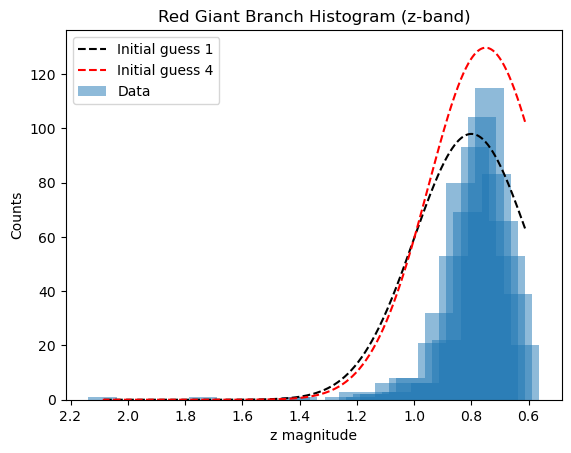

In [29]:
initial_guess_4 = [65.0, 0.75, 0.2]
plt.bar(bin_centers_m1z, hist_counts_m1z, width=0.1, alpha=0.5, label="Data")
x_fit = np.linspace(min(bin_centers_m1z), max(bin_centers_m1z), 500)
y_fit_1 = cgauss(x_fit, *initial_guess_1)
y_fit_4 = cgauss(x_fit, *initial_guess_4)
plt.plot(x_fit, y_fit_1, 'k--', label="Initial guess 1")
plt.plot(x_fit, y_fit_4, 'r--', label="Initial guess 4")
plt.xlabel("z magnitude")
plt.ylabel("Counts")
plt.title("Red Giant Branch Histogram (z-band)")
plt.legend()
plt.gca().invert_xaxis()
plt.show()

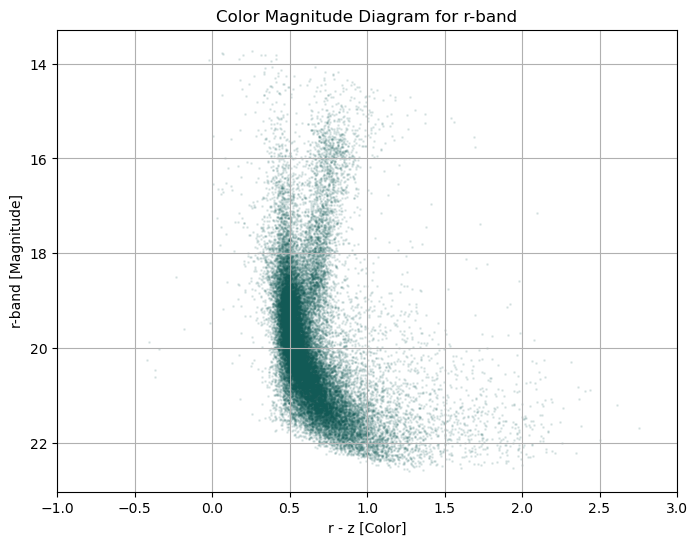

In [30]:
# Plot CMD for r-mag
cmd_fig = plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(color_index, magnitude_values_r, s = 1, color = '#125A56', alpha = 0.1)

plt.xlim(-1,3)
plt.gca().invert_yaxis()  # Brighter stars at the top

plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"{magnitude_band}-band [Magnitude]")

plt.title("Color Magnitude Diagram for r-band")
plt.grid(True)

#plt.savefig("debug_cmd_all_stars.png")
#if interactive_mode:
    #plt.show()
#plt.close(cmd_fig)
plt.show()

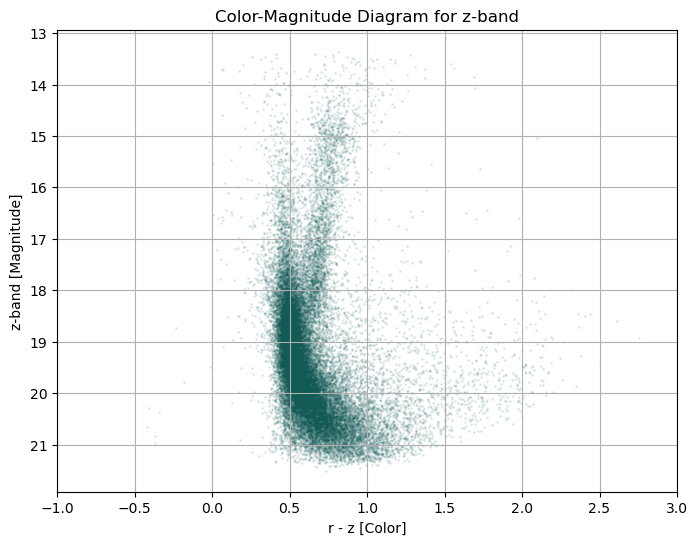

In [31]:
# Plot CMD for z-mag
cmd_fig = plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(color_index, magnitude_values_z, s = 1, color = '#125A56', alpha = 0.1)

plt.xlim(-1,3)
plt.gca().invert_yaxis()  # Brighter stars at the top

plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"{color_band_2}-band [Magnitude]")

plt.title("Color-Magnitude Diagram for z-band")
plt.grid(True)

#plt.savefig("debug_cmd_all_stars.png")
#if interactive_mode:
    #plt.show()
#plt.close(cmd_fig)
plt.show()

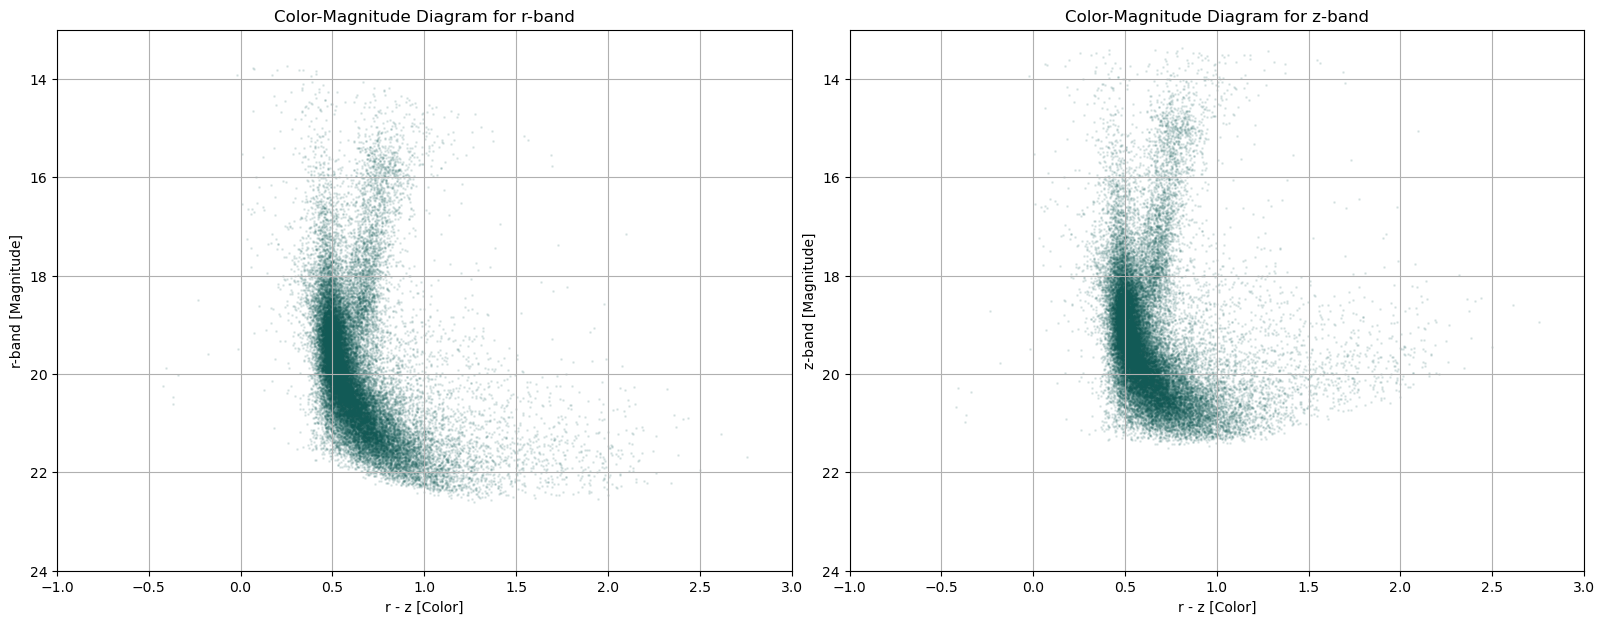

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot CMD for r-mag on the first subplot (ax1) ---
ax1.scatter(color_index, magnitude_values_r, s=1, color='#125A56', alpha=0.1)

ax1.set_xlim(-1, 3)
ax1.invert_yaxis() # Brighter stars at the top
ax1.set_ylim(24, 13)

ax1.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax1.set_ylabel(f"{magnitude_band}-band [Magnitude]")
ax1.set_title("Color-Magnitude Diagram for r-band")
ax1.grid(True)

# --- Plot CMD for z-mag on the second subplot (ax2) ---
ax2.scatter(color_index, magnitude_values_z, s=1, color='#125A56', alpha=0.1)

ax2.set_xlim(-1, 3)
ax2.invert_yaxis() # Brighter stars at the top
ax2.set_ylim(24, 13)

ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax2.set_ylabel(f"{color_band_2}-band [Magnitude]") 
ax2.set_title("Color-Magnitude Diagram for z-band")
ax2.grid(True)

plt.show()

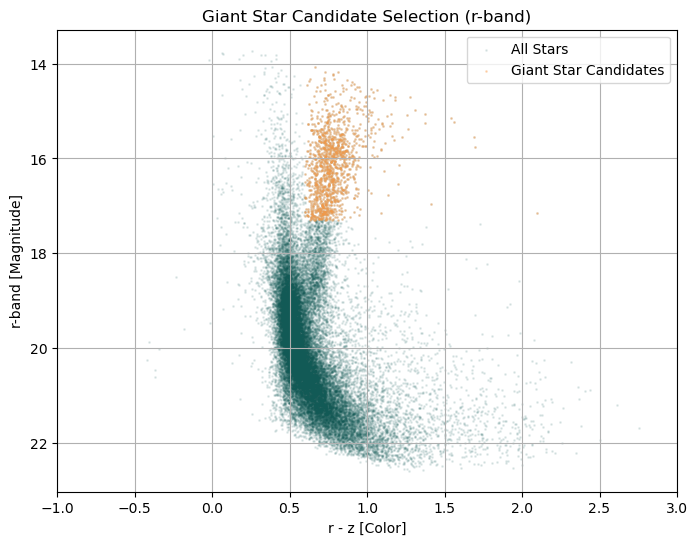

In [33]:
# Plot Giant Star Candidates on CMD for r-mag
giant_fig = plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(color_index, magnitude_values_r, s = 1, color = '#125A56', alpha = 0.1, label = 'All Stars')
plt.scatter(giant_colors, giant_magnitudes, s = 1, color = '#FD9A44', alpha = 0.3, label = 'Giant Star Candidates')

plt.xlim(-1,3)
plt.gca().invert_yaxis()

plt.title("Giant Star Candidate Selection (r-band)")
plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"{magnitude_band}-band [Magnitude]")

plt.grid(True)
plt.legend(loc = 'best')

#plt.savefig("debug_cmd_giant_candidates.png")
#if interactive_mode:
    #plt.show()
#plt.close(giant_fig)
plt.show()

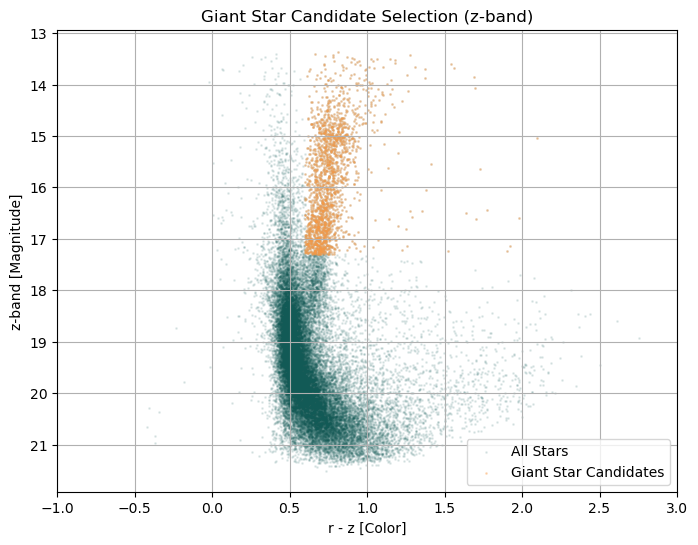

In [34]:
# Plot Giant Star Candidates on CMD for z-mag
giant_fig = plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(color_index, magnitude_values_z, s = 1, color = '#125A56', alpha = 0.1, label = 'All Stars')
plt.scatter(giant_colors_z, giant_magnitudes_z, s = 1, color = '#FD9A44', alpha = 0.3, label = 'Giant Star Candidates')

plt.xlim(-1,3)
plt.gca().invert_yaxis()

plt.title("Giant Star Candidate Selection (z-band)")
plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"{color_band_2}-band [Magnitude]")

plt.grid(True)
plt.legend(loc = 'best')

#plt.savefig("debug_cmd_giant_candidates.png")
#if interactive_mode:
    #plt.show()
#plt.close(giant_fig)
plt.show()

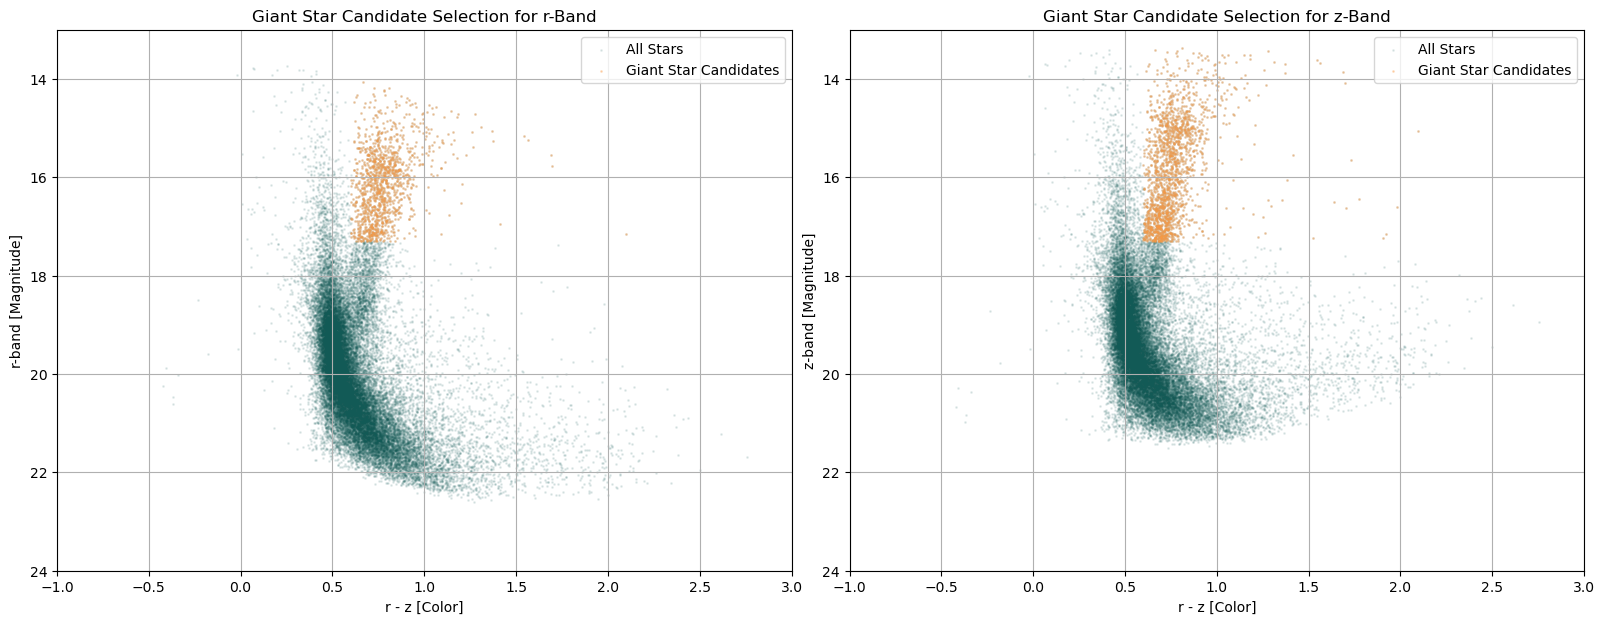

In [35]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot CMD for r-mag on the first subplot (ax1) ---
ax1.scatter(color_index, magnitude_values_r, s=1, color='#125A56', alpha=0.1, label = 'All Stars')
ax1.scatter(giant_colors, giant_magnitudes, s = 1, color = '#FD9A44', alpha = 0.3, label = 'Giant Star Candidates')

ax1.set_xlim(-1, 3)
ax1.invert_yaxis() # Brighter stars at the top
ax1.set_ylim(24, 13)

ax1.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax1.set_ylabel(f"{magnitude_band}-band [Magnitude]")
ax1.set_title("Giant Star Candidate Selection for r-Band")
ax1.grid(True)

ax1.legend(loc = 'best')

# --- Plot CMD for z-mag on the second subplot (ax2) ---
ax2.scatter(color_index, magnitude_values_z, s=1, color='#125A56', alpha=0.1, label = 'All Stars')
ax2.scatter(giant_colors_z, giant_magnitudes_z, s = 1, color = '#FD9A44', alpha = 0.3, label = 'Giant Star Candidates')

ax2.set_xlim(-1, 3)
ax2.invert_yaxis() # Brighter stars at the top
ax2.set_ylim(24, 13)

ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax2.set_ylabel(f"{color_band_2}-band [Magnitude]") 
ax2.set_title("Giant Star Candidate Selection for z-Band")
ax2.grid(True)

ax2.legend(loc = 'best')

plt.show()

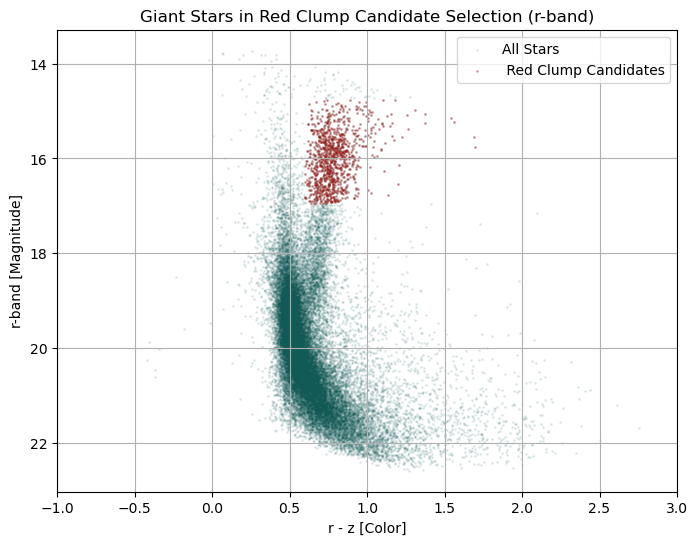

In [36]:
# Plot Red Clump Giant Star Candidates on CMD for r-mag
clump_fig = plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(color_index, magnitude_values_r, s = 1, color = '#125A56', alpha = 0.1, label = 'All Stars')
plt.scatter(clump_colors, clump_magnitudes, s = 1, color = '#A01813', alpha = 0.3, label = ' Red Clump Candidates')

plt.xlim(-1,3)
plt.gca().invert_yaxis()

plt.title("Giant Stars in Red Clump Candidate Selection (r-band)")
plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"{magnitude_band}-band [Magnitude]")

plt.grid(True)
plt.legend(loc='best')

#plt.savefig("debug_cmd_clump_candidates.png")
#if interactive_mode:
    #plt.show()
#plt.close(clump_fig)
plt.show()

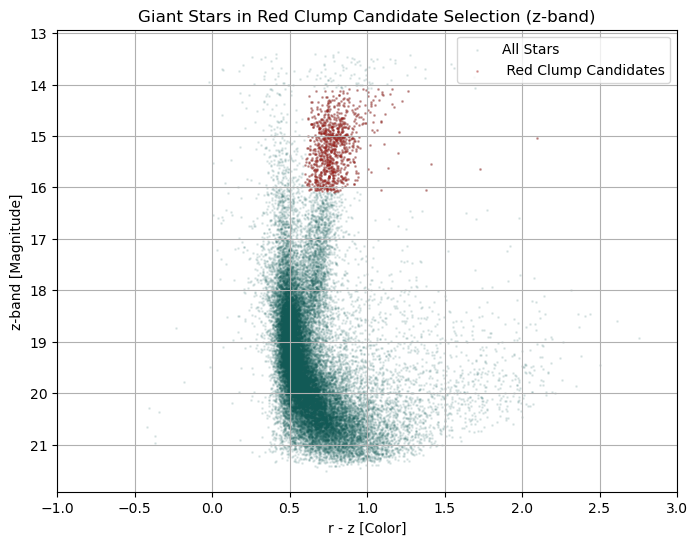

In [37]:
# Plot Red Clump Giant Star Candidates on CMD for z-mag
clump_fig = plt.figure(figsize = (8, 6))
plt.tight_layout()

plt.scatter(color_index, magnitude_values_z, s = 1, color = '#125A56', alpha = 0.1, label = 'All Stars')
plt.scatter(clump_colors_z, clump_magnitudes_z, s = 1, color = '#A01813', alpha = 0.3, label = ' Red Clump Candidates')

plt.xlim(-1,3)
plt.gca().invert_yaxis()

plt.title("Giant Stars in Red Clump Candidate Selection (z-band)")
plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"{color_band_2}-band [Magnitude]")

plt.grid(True)
plt.legend(loc='best')

#plt.savefig("debug_cmd_clump_candidates.png")
#if interactive_mode:
    #plt.show()
#plt.close(clump_fig)
plt.show()

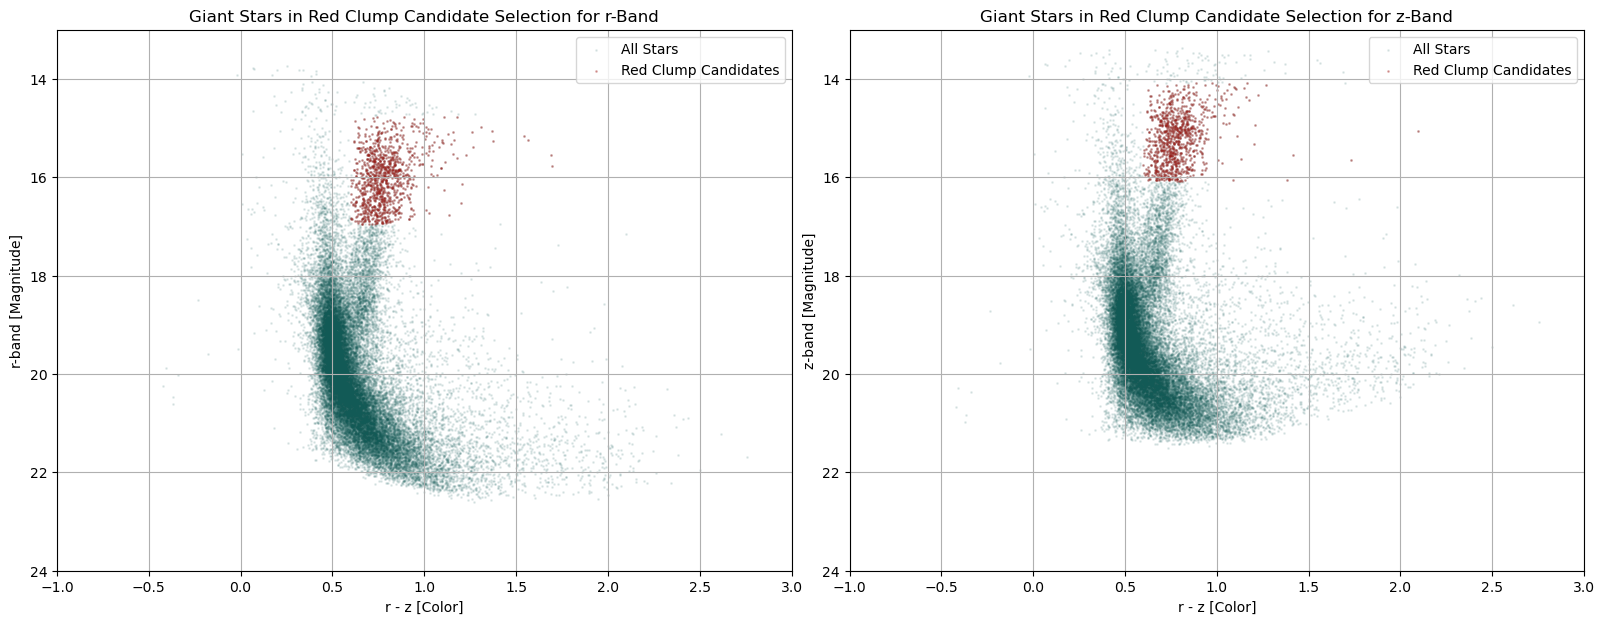

In [38]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot CMD for r-mag on the first subplot (ax1) ---
ax1.scatter(color_index, magnitude_values_r, s = 1, color='#125A56', alpha=0.1, label = 'All Stars')
ax1.scatter(clump_colors, clump_magnitudes, s = 1, color = '#A01813', alpha = 0.3, label = 'Red Clump Candidates')

ax1.set_xlim(-1, 3)
ax1.invert_yaxis() # Brighter stars at the top
ax1.set_ylim(24, 13)

ax1.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax1.set_ylabel(f"{magnitude_band}-band [Magnitude]")
ax1.set_title("Giant Stars in Red Clump Candidate Selection for r-Band")
ax1.grid(True)

ax1.legend(loc = 'best')

# --- Plot CMD for z-mag on the second subplot (ax2) ---
ax2.scatter(color_index, magnitude_values_z, s=1, color='#125A56', alpha=0.1, label = 'All Stars')
ax2.scatter(clump_colors_z, clump_magnitudes_z, s = 1, color = '#A01813', alpha = 0.3, label = 'Red Clump Candidates')

ax2.set_xlim(-1, 3)
ax2.invert_yaxis() # Brighter stars at the top
ax2.set_ylim(24, 13)

ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax2.set_ylabel(f"{color_band_2}-band [Magnitude]") 
ax2.set_title("Giant Stars in Red Clump Candidate Selection for z-Band")
ax2.grid(True)

ax2.legend(loc = 'best')

plt.show()

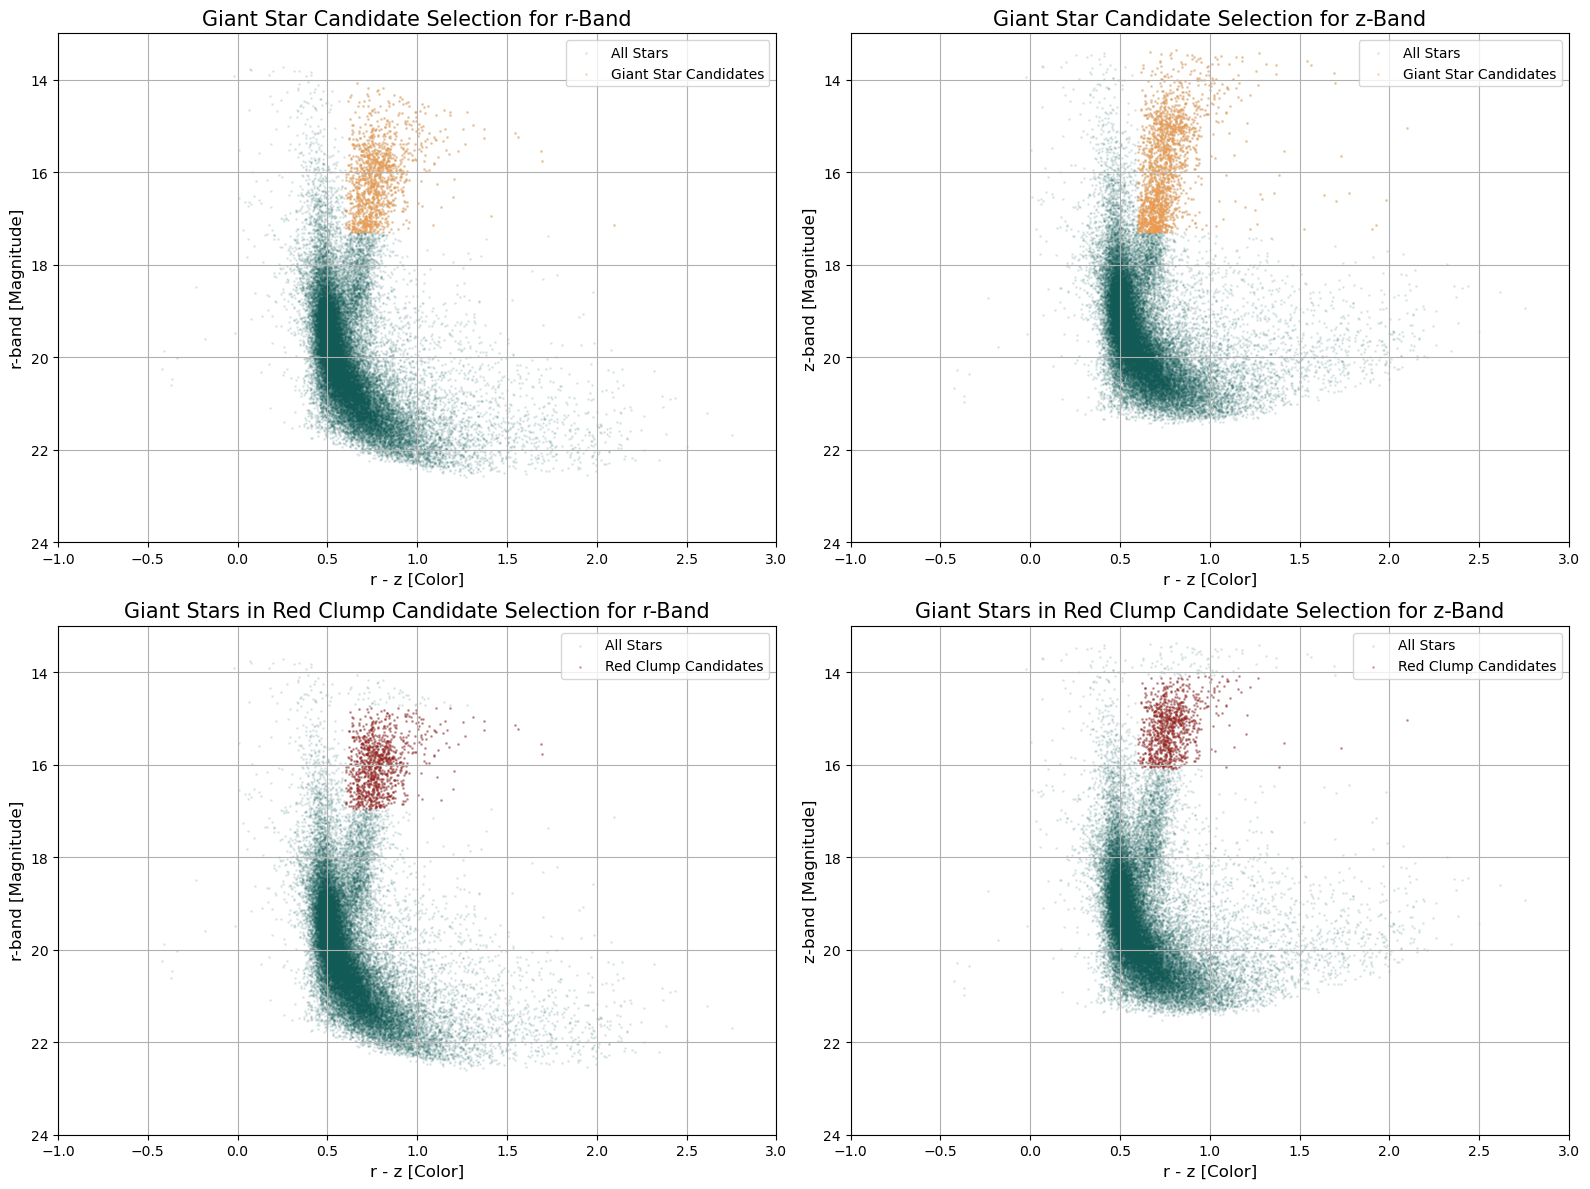

In [39]:
# Create one figure with 2 rows × 2 columns, each row height = 6
fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(2, 2, height_ratios=[6, 6])

# === Top-left: Giant star candidates (r-band) ===
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(color_index, magnitude_values_r, s=1, color='#125A56', alpha=0.1, label='All Stars')
ax1.scatter(giant_colors, giant_magnitudes, s=1, color='#FD9A44', alpha=0.3, label='Giant Star Candidates')
ax1.set_xlim(-1, 3)
ax1.set_ylim(13, 24)
ax1.invert_yaxis()
ax1.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax1.set_ylabel(f"{magnitude_band}-band [Magnitude]", fontsize = 12)
ax1.set_title("Giant Star Candidate Selection for r-Band", fontsize = 15)
ax1.grid(True)
ax1.legend(loc='best')

# === Top-right: Giant star candidates (z-band) ===
ax2 = fig.add_subplot(gs[0, 1])
ax2.scatter(color_index, magnitude_values_z, s=1, color='#125A56', alpha=0.1, label='All Stars')
ax2.scatter(giant_colors_z, giant_magnitudes_z, s=1, color='#FD9A44', alpha=0.3, label='Giant Star Candidates')
ax2.set_xlim(-1, 3)
ax2.set_ylim(13, 24)
ax2.invert_yaxis()
ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax2.set_ylabel(f"{color_band_2}-band [Magnitude]", fontsize = 12)
ax2.set_title("Giant Star Candidate Selection for z-Band", fontsize = 15)
ax2.grid(True)
ax2.legend(loc='best')

# === Bottom-left: Red clump candidates (r-band) ===
ax3 = fig.add_subplot(gs[1, 0])
ax3.scatter(color_index, magnitude_values_r, s=1, color='#125A56', alpha=0.1, label='All Stars')
ax3.scatter(clump_colors, clump_magnitudes, s=1, color='#A01813', alpha=0.3, label='Red Clump Candidates')
ax3.set_xlim(-1, 3)
ax3.set_ylim(13, 24)
ax3.invert_yaxis()
ax3.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax3.set_ylabel(f"{magnitude_band}-band [Magnitude]", fontsize = 12)
ax3.set_title("Giant Stars in Red Clump Candidate Selection for r-Band", fontsize = 15)
ax3.grid(True)
ax3.legend(loc='best')

# === Bottom-right: Red clump candidates (z-band) ===
ax4 = fig.add_subplot(gs[1, 1])
ax4.scatter(color_index, magnitude_values_z, s=1, color='#125A56', alpha=0.1, label='All Stars')
ax4.scatter(clump_colors_z, clump_magnitudes_z, s=1, color='#A01813', alpha=0.3, label='Red Clump Candidates')
ax4.set_xlim(-1, 3)
ax4.set_ylim(13, 24)
ax4.invert_yaxis()
ax4.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax4.set_ylabel(f"{color_band_2}-band [Magnitude]", fontsize = 12)
ax4.set_title("Giant Stars in Red Clump Candidate Selection for z-Band", fontsize = 15)
ax4.grid(True)
ax4.legend(loc='best')

plt.tight_layout()
plt.savefig('figures/rz_cmd_sub4.png')

plt.show()

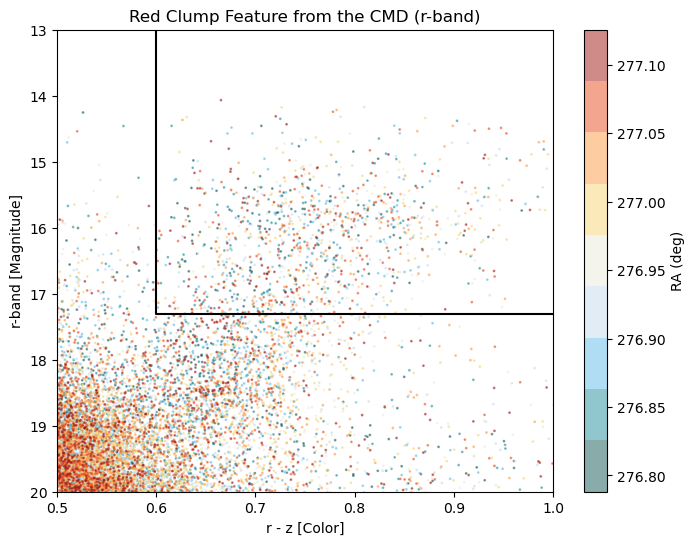

In [40]:
# Get the custom colormap
nightfall_cmap = tol_cmap('nightfall_discrete')

# Plot CMD zoomed in on red clump region and color-coded by RA
plt.figure(figsize=(8, 6))
plt.tight_layout()

sc = plt.scatter(
    color_index,
    magnitude_values_r,
    c = filtered_catalog[:, ra_col_index],
    cmap = nightfall_cmap,  # <-- apply the color map here
    s = 1,
    alpha = 0.5,
    rasterized = True
)

plt.plot([default_color_cut, default_color_cut, color_range_max],
         [13.0, magnitude_cut, magnitude_cut], 'k-')
plt.colorbar(sc, label = 'RA (deg)')

plt.xlim(0.5, color_range_max)
plt.ylim(20, 13)

plt.title('Red Clump Feature from the CMD (r-band)')
plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"{magnitude_band}-band [Magnitude]")

plt.show()

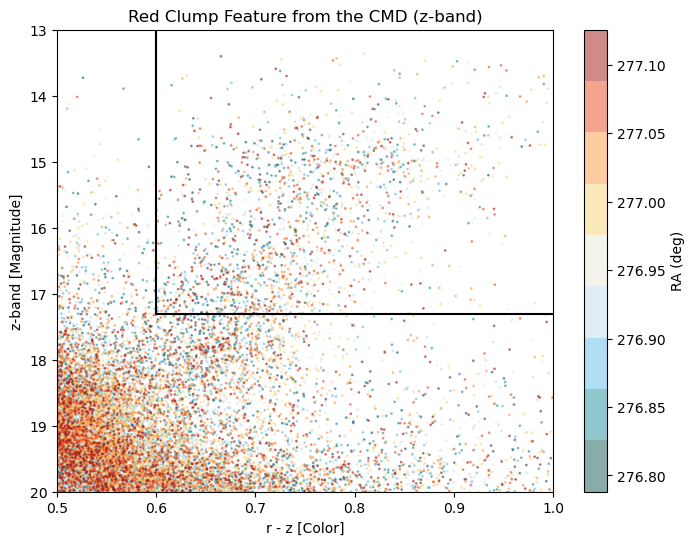

In [41]:
# Plot CMD zoomed in on red clump region and color-coded by RA
plt.figure(figsize=(8, 6))
plt.tight_layout()

sc = plt.scatter(
    color_index,
    magnitude_values_z,
    c = filtered_catalog[:, ra_col_index],
    cmap = nightfall_cmap,  # <-- apply the color map here
    s = 1,
    alpha = 0.5,
    rasterized = True
)

plt.plot([default_color_cut, default_color_cut, color_range_max],
         [13.0, magnitude_cut, magnitude_cut], 'k-')
plt.colorbar(sc, label='RA (deg)')

plt.xlim(0.5, color_range_max)
plt.ylim(20, 13)

plt.title('Red Clump Feature from the CMD (z-band)')
plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"{color_band_2}-band [Magnitude]")

plt.show()

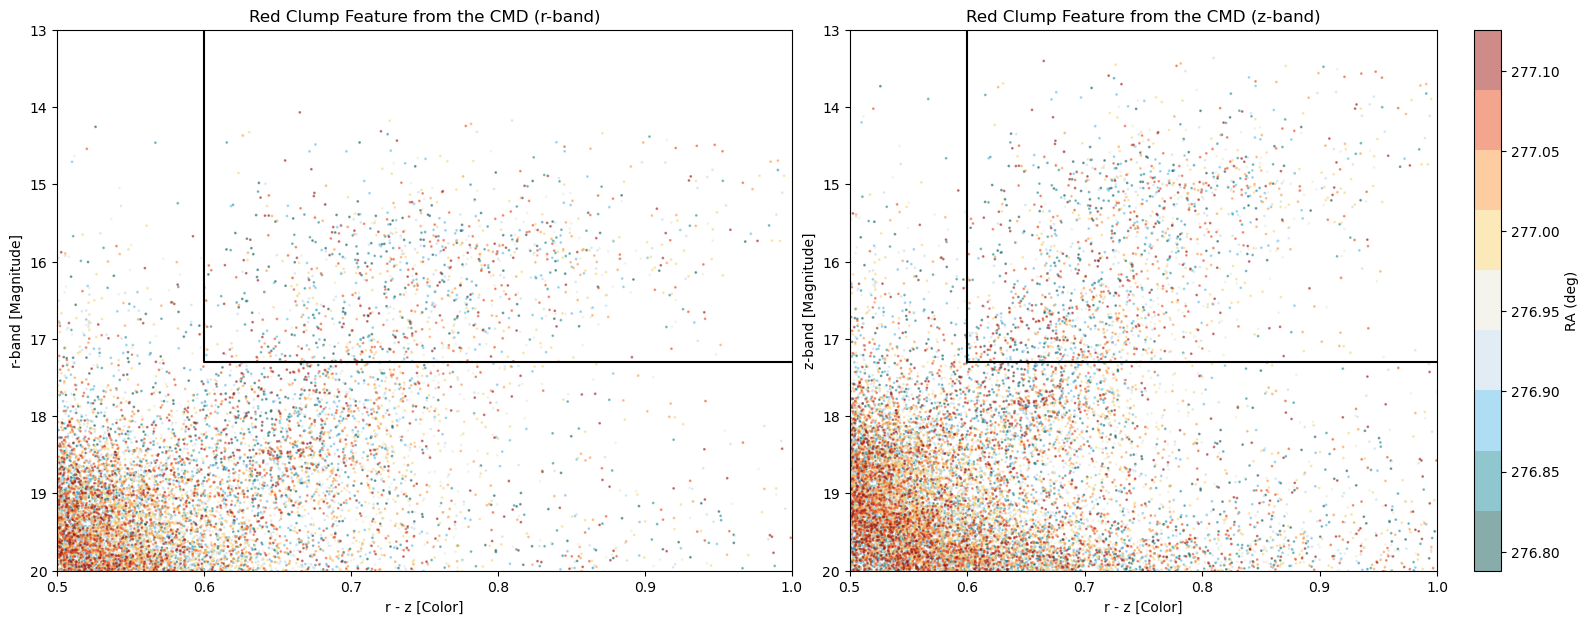

In [42]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot Red Clump feature from CMD for r-mag on the first subplot (ax1) ---
sc = ax1.scatter(
    color_index,
    magnitude_values_r,
    c = filtered_catalog[:, ra_col_index],
    cmap = nightfall_cmap,  # <-- apply the color map here
    s = 1,
    alpha = 0.5,
    rasterized = True
)

ax1.plot([default_color_cut, default_color_cut, color_range_max],
         [13.0, magnitude_cut, magnitude_cut], 'k-')

ax1.set_xlim(0.5, color_range_max)
ax1.set_ylim(20, 13)

ax1.set_title('Red Clump Feature from the CMD (r-band)')
ax1.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax1.set_ylabel(f"{magnitude_band}-band [Magnitude]")

# --- Plot Red Clump feature from CMD for z-mag on the second subplot (ax2) ---
sc_2 = ax2.scatter(
    color_index,
    magnitude_values_z,
    c = filtered_catalog[:, ra_col_index],
    cmap = nightfall_cmap,  # <-- apply the color map here
    s = 1,
    alpha = 0.5,
    rasterized = True
)

ax2.plot([default_color_cut, default_color_cut, color_range_max],
         [13.0, magnitude_cut, magnitude_cut], 'k-')

ax2.set_xlim(0.5, color_range_max)
ax2.set_ylim(20, 13)

ax2.set_title('Red Clump Feature from the CMD (z-band)')
ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax2.set_ylabel(f"{color_band_2}-band [Magnitude]")

plt.colorbar(sc_2, label='RA (deg)')
plt.show()

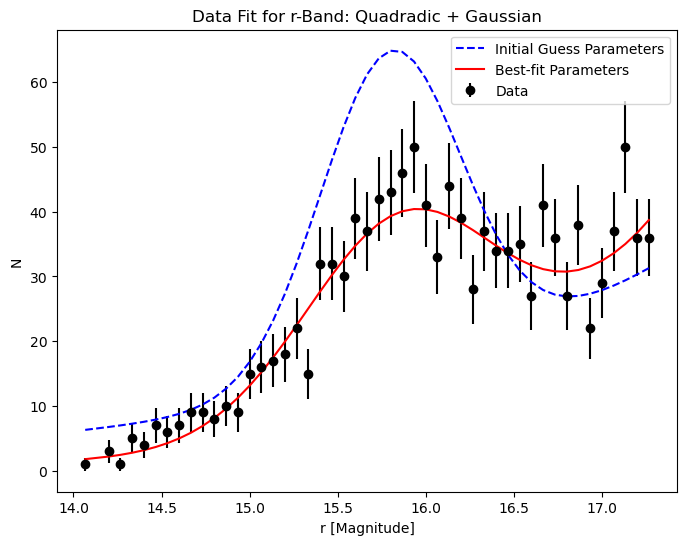

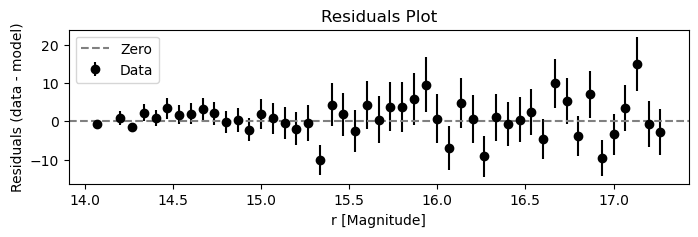

r_rc = 15.856 ± 0.044, sigma_rc =  0.549 ± 0.053, A_r = 0.780 ± 0.044


In [43]:
plt.figure(figsize=(8,6))
plt.tight_layout()

plt.errorbar(bin_centers_m0, hist_counts_m0, yerr = np.sqrt(hist_counts_m0), fmt = 'ko', label = 'Data') 

# Compute residuals
model_vals_0 = rcmodel_r(bin_centers_m0, *par_0)
residuals_0 = hist_counts_m0 - model_vals_0

plt.plot(bin_centers_m0, rcmodel_r(bin_centers_m0, *initial_guess_2), 'b--', label = 'Initial Guess Parameters')
plt.plot(bin_centers_m0, rcmodel_r(bin_centers_m0, *par_0), 'r-', label = 'Best-fit Parameters')

plt.xlabel(f"{magnitude_band} [Magnitude]")
plt.ylabel(f"N")
plt.title('Data Fit for r-Band: Quadradic + Gaussian')

plt.legend(loc='best')
plt.show()

# Plot residuals
plt.figure(figsize = (8, 2))
plt.tight_layout()

plt.errorbar(bin_centers_m0, residuals_0, yerr = np.sqrt(hist_counts_m0), fmt = 'ko', label = 'Data')
plt.axhline(0, color ='gray', linestyle ='--', label = 'Zero')

plt.xlabel(f"{magnitude_band} [Magnitude]")
plt.ylabel('Residuals (data - model)')
plt.title('Residuals Plot')

plt.legend(loc = 'best')
plt.show()

print(
    f"{magnitude_band}_rc = {par_0[2]:6.3f} ± {np.sqrt(cov_0[2, 2]):5.3f}, "
    f"sigma_rc = {par_0[4]:6.3f} ± {np.sqrt(cov_0[4, 4]):5.3f}, "
    f"A_{magnitude_band} = {par_0[2] - clumpmag0_r:5.3f} ± {np.sqrt(cov_0[2, 2]):5.3f}"
)

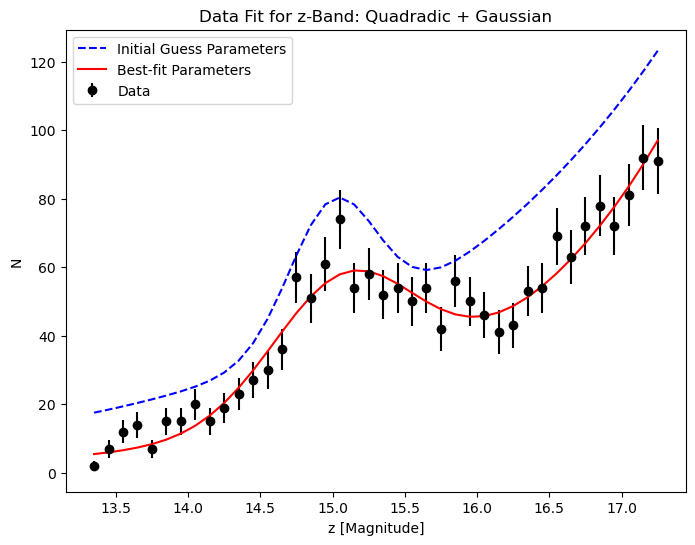

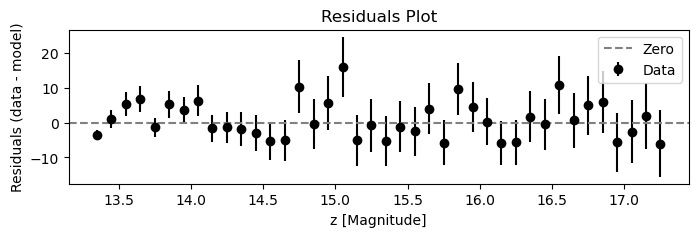

z_rc = 15.079 ± 0.040, sigma_rc =  0.501 ± 0.049, A_z = 0.416 ± 0.040


In [44]:
plt.figure(figsize=(8,6))
plt.tight_layout()

plt.errorbar(bin_centers_m0z, hist_counts_m0z, yerr = np.sqrt(hist_counts_m0z), fmt = 'ko', label = 'Data') 

# Compute residuals
model_vals_0z = rcmodel_z(bin_centers_m0z, *par_0z)
residuals_0z = hist_counts_m0z - model_vals_0z

plt.plot(bin_centers_m0z, rcmodel_z(bin_centers_m0z, *initial_guess_0), 'b--', label = 'Initial Guess Parameters')
plt.plot(bin_centers_m0z, rcmodel_z(bin_centers_m0z, *par_0z), 'r-', label = 'Best-fit Parameters')

plt.xlabel(f"{color_band_2} [Magnitude]")
plt.ylabel(f"N")
plt.title('Data Fit for z-Band: Quadradic + Gaussian')

plt.legend(loc='best')
plt.show()

# Plot residuals
plt.figure(figsize = (8, 2))
plt.tight_layout()

plt.errorbar(bin_centers_m0z, residuals_0z, yerr = np.sqrt(hist_counts_m0z), fmt = 'ko', label = 'Data')
plt.axhline(0, color ='gray', linestyle ='--', label = 'Zero')

plt.xlabel(f"{color_band_2} [Magnitude]")
plt.ylabel('Residuals (data - model)')
plt.title('Residuals Plot')

plt.legend(loc = 'best')
plt.show()

print(
    f"{color_band_2}_rc = {par_0z[2]:6.3f} ± {np.sqrt(cov_0z[2, 2]):5.3f}, "
    f"sigma_rc = {par_0z[4]:6.3f} ± {np.sqrt(cov_0z[4, 4]):5.3f}, "
    f"A_{color_band_2} = {par_0z[2] - clumpmag0_z:5.3f} ± {np.sqrt(cov_0z[2, 2]):5.3f}"
)

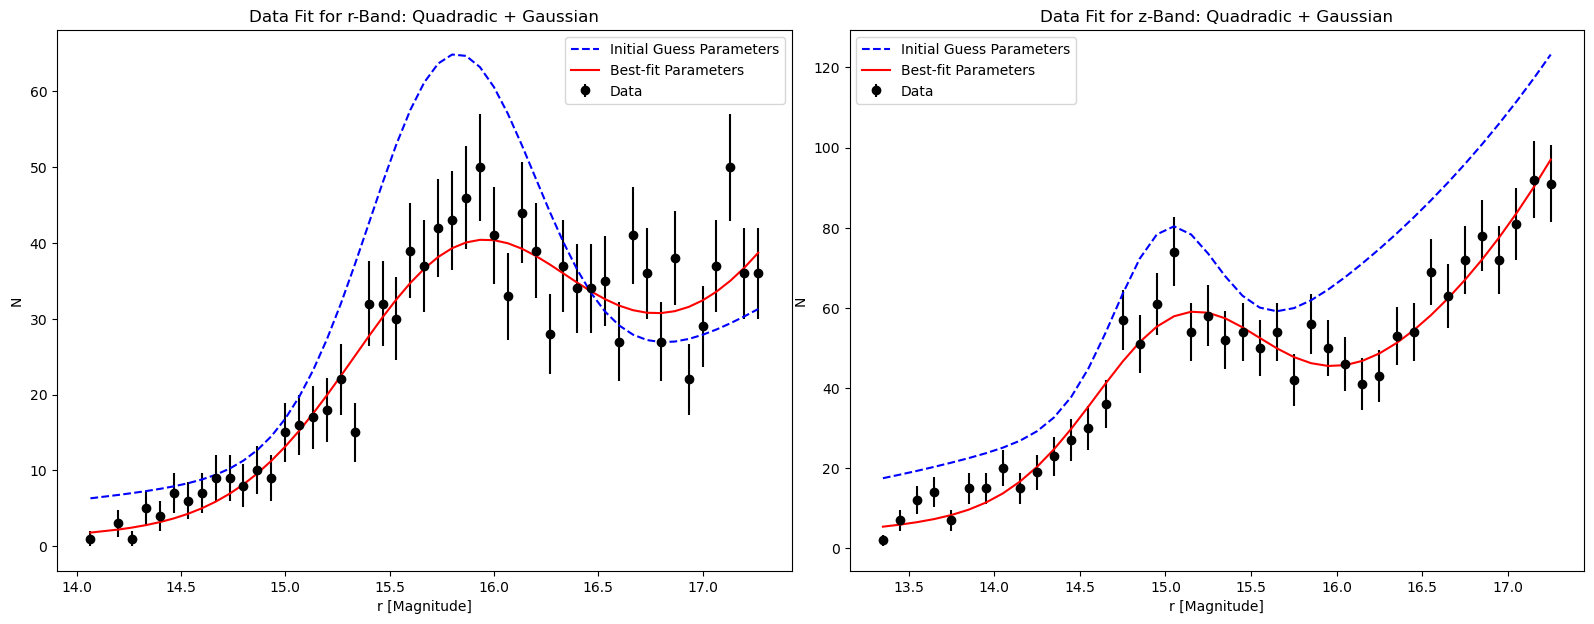

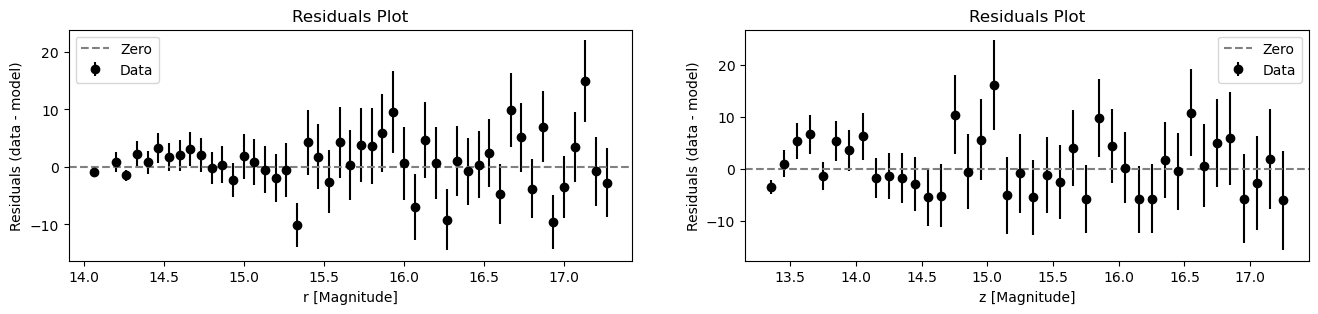

In [45]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot rcmodel Data Fit of Giant Stars for r-mag on the first subplot (ax1) ---
ax1.errorbar(bin_centers_m0, hist_counts_m0, yerr = np.sqrt(hist_counts_m0), fmt = 'ko', label = 'Data') 
ax1.plot(bin_centers_m0, rcmodel_r(bin_centers_m0, *initial_guess_2), 'b--', label = 'Initial Guess Parameters')
ax1.plot(bin_centers_m0, rcmodel_r(bin_centers_m0, *par_0), 'r-', label = 'Best-fit Parameters')

ax1.set_xlabel(f"{magnitude_band} [Magnitude]")
ax1.set_ylabel(f"N")
ax1.set_title('Data Fit for r-Band: Quadradic + Gaussian')

ax1.legend(loc='best')

# --- Plot rcmodel Data Fit of Giant Stars CMD for z-mag on the second subplot (ax2) ---
ax2.errorbar(bin_centers_m0z, hist_counts_m0z, yerr = np.sqrt(hist_counts_m0z), fmt = 'ko', label = 'Data') 

ax2.plot(bin_centers_m0z, rcmodel_z(bin_centers_m0z, *initial_guess_0), 'b--', label = 'Initial Guess Parameters')
ax2.plot(bin_centers_m0z, rcmodel_z(bin_centers_m0z, *par_0z), 'r-', label = 'Best-fit Parameters')

ax2.set_xlabel(f"{magnitude_band} [Magnitude]")
ax2.set_ylabel(f"N")
ax2.set_title('Data Fit for z-Band: Quadradic + Gaussian')

ax2.legend(loc='best')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 3)) # Increased width for side-by-side
# plt.tight_layout()

# --- Plot residuals for r-mag on the first subplot (ax1) ---
ax1.errorbar(bin_centers_m0, residuals_0, yerr = np.sqrt(hist_counts_m0), fmt = 'ko', label = 'Data')
ax1.axhline(0, color ='gray', linestyle ='--', label = 'Zero')

ax1.set_xlabel(f"{magnitude_band} [Magnitude]")
ax1.set_ylabel('Residuals (data - model)')
ax1.set_title('Residuals Plot')

ax1.legend(loc = 'best')

# --- Plot residuals for z-mag on the second subplot (ax2) ---
ax2.errorbar(bin_centers_m0z, residuals_0z, yerr = np.sqrt(hist_counts_m0z), fmt = 'ko', label = 'Data')
ax2.axhline(0, color ='gray', linestyle ='--', label = 'Zero')

ax2.set_xlabel(f"{color_band_2} [Magnitude]")
ax2.set_ylabel('Residuals (data - model)')
ax2.set_title('Residuals Plot')

ax2.legend(loc = 'best')
plt.show()

/tmp/slurmtmp.8985486/ipykernel_2816408/515598045.py:10: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax1.errorbar(bin_centers_m0, hist_counts_m0, yerr=np.sqrt(hist_counts_m0), fmt='o', color = '#125A56', marker = 'o',
/tmp/slurmtmp.8985486/ipykernel_2816408/515598045.py:22: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax2.errorbar(bin_centers_m0z, hist_counts_m0z, yerr=np.sqrt(hist_counts_m0z), fmt='o', color = '#125A56', marker = 'o',
/tmp/slurmtmp.8985486/ipykernel_2816408/515598045.py:34: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax3.errorbar(bin_centers_m0, residuals_0, yerr=np.sqrt(hist_counts_m0), fmt='o', color = '#125A56', marker = 

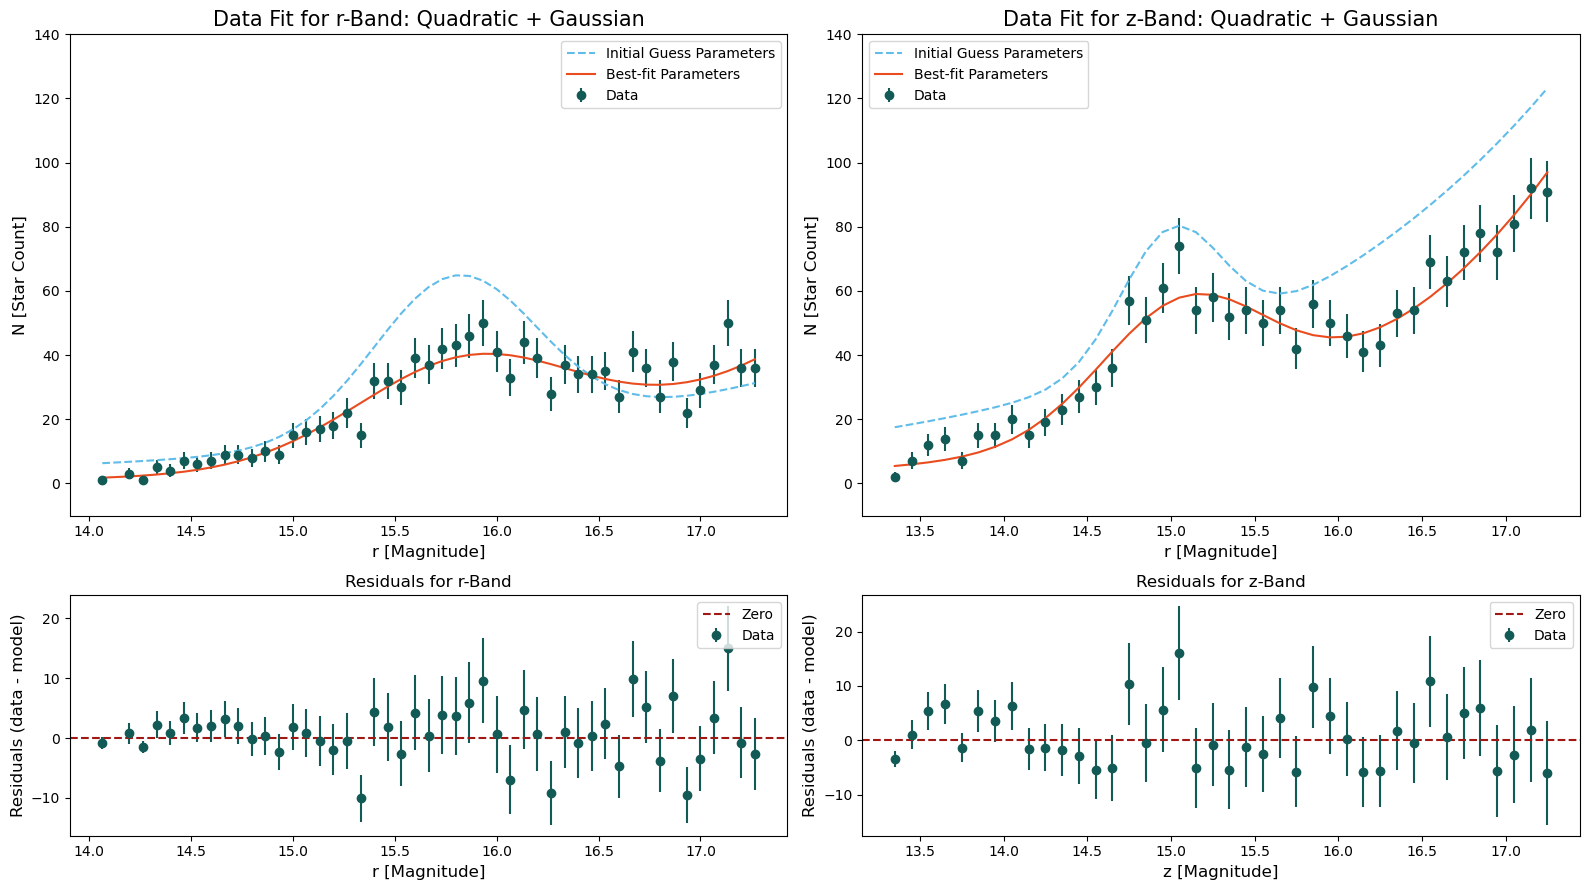

In [46]:
clrs = ['#125A56', '#238F9D', '#60BCE9', '#C6DBED', '#ECEADA',
                '#F9D576', '#FD9A44', '#E94C1F', '#A01813']

# Create figure with total height = 6 + 3 = 9, width = 16
fig = plt.figure(figsize=(16, 9))
gs = gridspec.GridSpec(2, 2, height_ratios=[6, 3])  # Top row taller than bottom

# === Top-left: r-band data fit ===
ax1 = fig.add_subplot(gs[0, 0])
ax1.errorbar(bin_centers_m0, hist_counts_m0, yerr=np.sqrt(hist_counts_m0), fmt='o', color = '#125A56', marker = 'o',
             label='Data') 
ax1.plot(bin_centers_m0, rcmodel_r(bin_centers_m0, *initial_guess_2), '#60BCE9', linestyle = '--', label='Initial Guess Parameters')
ax1.plot(bin_centers_m0, rcmodel_r(bin_centers_m0, *par_0), '#E94C1F', label='Best-fit Parameters')
ax1.set_ylim(-10, 140)
ax1.set_xlabel(f"{magnitude_band} [Magnitude]", fontsize = 12)
ax1.set_ylabel("N [Star Count]", fontsize = 12)
ax1.set_title("Data Fit for r-Band: Quadratic + Gaussian", fontsize = 15)
ax1.legend(loc='best')

# === Top-right: z-band data fit ===
ax2 = fig.add_subplot(gs[0, 1])
ax2.errorbar(bin_centers_m0z, hist_counts_m0z, yerr=np.sqrt(hist_counts_m0z), fmt='o', color = '#125A56', marker = 'o',
             label='Data') 
ax2.plot(bin_centers_m0z, rcmodel_z(bin_centers_m0z, *initial_guess_0),'#60BCE9', linestyle = '--', label='Initial Guess Parameters')
ax2.plot(bin_centers_m0z, rcmodel_z(bin_centers_m0z, *par_0z), '#E94C1F', label='Best-fit Parameters')
ax2.set_ylim(-10, 140)
ax2.set_xlabel(f"{magnitude_band} [Magnitude]", fontsize = 12)
ax2.set_ylabel("N [Star Count]", fontsize = 12)
ax2.set_title("Data Fit for z-Band: Quadratic + Gaussian", fontsize = 15)
ax2.legend(loc='best')

# === Bottom-left: residuals for r-band ===
ax3 = fig.add_subplot(gs[1, 0])
ax3.errorbar(bin_centers_m0, residuals_0, yerr=np.sqrt(hist_counts_m0), fmt='o', color = '#125A56', marker = 'o', label='Data')
ax3.axhline(0, color='#A01813', linestyle='--', label='Zero')
ax3.set_xlabel(f"{magnitude_band} [Magnitude]", fontsize = 12)
ax3.set_ylabel("Residuals (data - model)", fontsize = 12)
ax3.set_title("Residuals for r-Band", fontsize = 12)
ax3.legend(loc='best')

# === Bottom-right: residuals for z-band ===
ax4 = fig.add_subplot(gs[1, 1])
ax4.errorbar(bin_centers_m0z, residuals_0z, yerr=np.sqrt(hist_counts_m0z), fmt='o', color = '#125A56', marker = 'o', label='Data')
ax4.axhline(0, color='#A01813', linestyle='--', label='Zero')
ax4.set_xlabel(f"{color_band_2} [Magnitude]", fontsize = 12)
ax4.set_ylabel("Residuals (data - model)", fontsize = 12)
ax4.set_title("Residuals for z-Band", fontsize = 12)
ax4.legend(loc='best')

plt.tight_layout()
plt.savefig('figures/rz_rcfit_sub4.png')
plt.show()

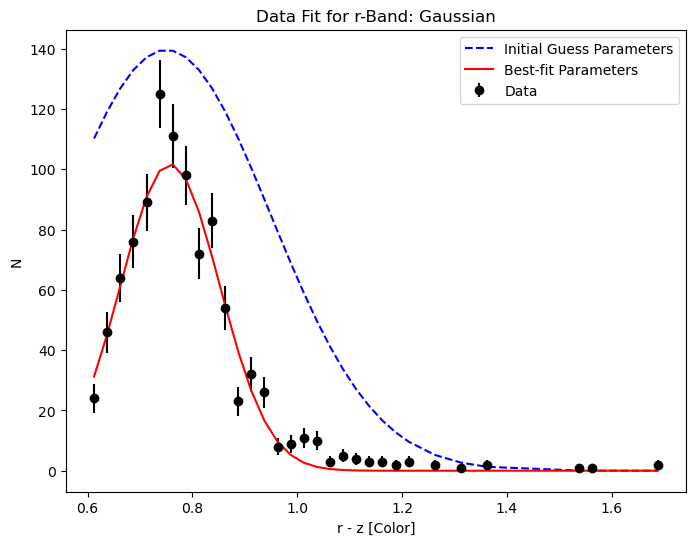

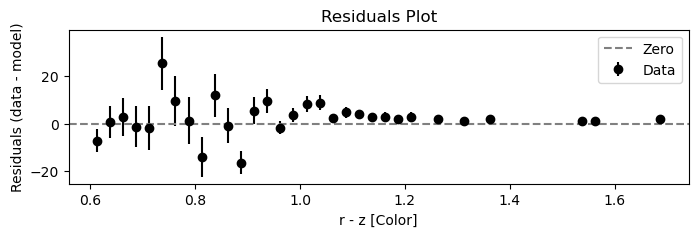

(r-z) = 0.758 ± 0.006, σ_(r-z) = 0.094 ± 0.005


In [47]:
plt.figure(figsize=(8,6))
plt.tight_layout()

plt.errorbar(bin_centers_m1, hist_counts_m1, yerr = np.sqrt(hist_counts_m1), fmt = 'ko', label = 'Data')

# Compute residuals
model_vals_1 = cgauss(bin_centers_m1, *par_1)
residuals_1 = hist_counts_m1 - model_vals_1

plt.plot(bin_centers_m1, cgauss(bin_centers_m1, *initial_guess_3), 'b--', label = 'Initial Guess Parameters')
plt.plot(bin_centers_m1, cgauss(bin_centers_m1, *par_1), 'r-', label = 'Best-fit Parameters')

plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"N")
plt.title('Data Fit for r-Band: Gaussian')

plt.legend(loc='best')
plt.show()

# Plot residuals
plt.figure(figsize=(8, 2))
plt.tight_layout()

plt.errorbar(bin_centers_m1, residuals_1, yerr=np.sqrt(hist_counts_m1), fmt='ko', label = 'Data')
plt.axhline(0, color='gray', linestyle='--', label = 'Zero')

plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel('Residuals (data - model)')
plt.title('Residuals Plot')

plt.legend(loc = 'best')
plt.show()

print(rf"({color_band_1}-{color_band_2}) = {par_1[1]:.3f} ± {np.sqrt(cov_1[1,1]):.3f}, σ_({color_band_1}-{color_band_2}) = {par_1[2]:.3f} ± {np.sqrt(cov_1[2,2]):.3f}")

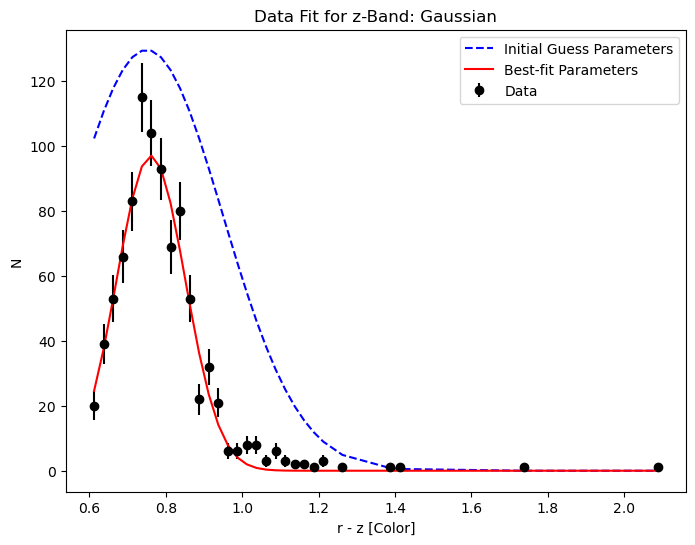

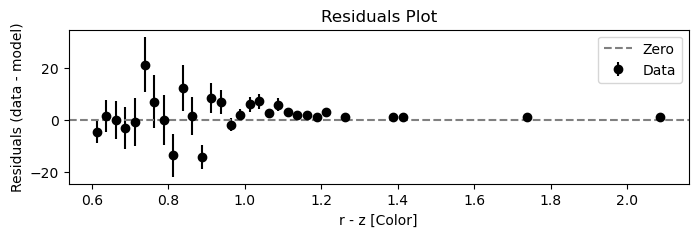

(r-z) = 0.761 ± 0.005, σ_(r-z) = 0.090 ± 0.005


In [48]:
plt.figure(figsize=(8,6))
plt.tight_layout()

plt.errorbar(bin_centers_m1z, hist_counts_m1z, yerr = np.sqrt(hist_counts_m1z), fmt = 'ko', label = 'Data')

# Compute residuals
model_vals_1z = cgauss(bin_centers_m1z, *par_1z)
residuals_1z = hist_counts_m1z - model_vals_1z

plt.plot(bin_centers_m1z, cgauss(bin_centers_m1z, *initial_guess_4), 'b--', label = 'Initial Guess Parameters')
plt.plot(bin_centers_m1z, cgauss(bin_centers_m1z, *par_1z), 'r-', label = 'Best-fit Parameters')

plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"N")
plt.title('Data Fit for z-Band: Gaussian')

plt.legend(loc='best')
plt.show()

# Plot residuals
plt.figure(figsize=(8, 2))
plt.tight_layout()

plt.errorbar(bin_centers_m1z, residuals_1z, yerr=np.sqrt(hist_counts_m1z), fmt='ko', label = 'Data')
plt.axhline(0, color='gray', linestyle='--', label = 'Zero')

plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel('Residuals (data - model)')
plt.title('Residuals Plot')

plt.legend(loc = 'best')
plt.show()

print(rf"({color_band_1}-{color_band_2}) = {par_1z[1]:.3f} ± {np.sqrt(cov_1z[1,1]):.3f}, σ_({color_band_1}-{color_band_2}) = {par_1z[2]:.3f} ± {np.sqrt(cov_1z[2,2]):.3f}")

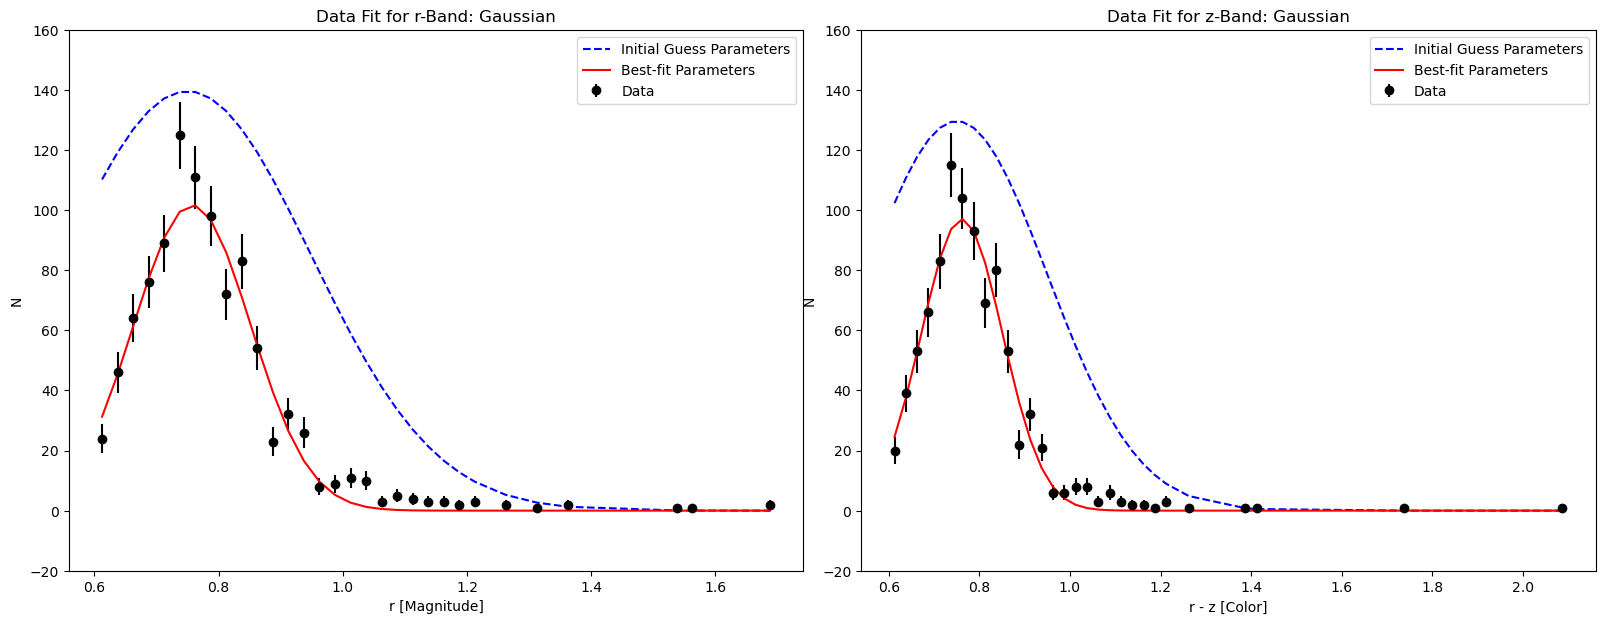

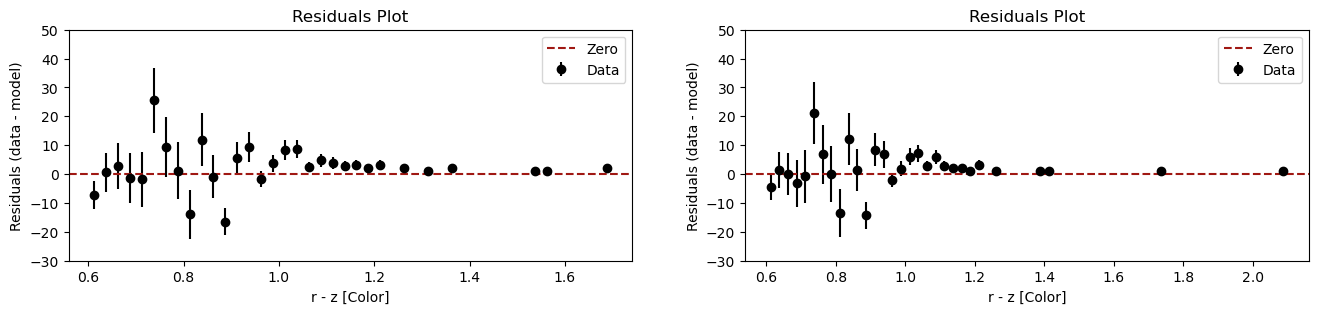

In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6)) # Increased width for side-by-side
plt.tight_layout()

# --- Plot cgauss Data Fit of Giant Stars in the Red Clump for r-mag on the first subplot (ax1) ---
ax1.errorbar(bin_centers_m1, hist_counts_m1, yerr = np.sqrt(hist_counts_m1), fmt = 'ko', label = 'Data') 
ax1.plot(bin_centers_m1, cgauss(bin_centers_m1, *initial_guess_3), 'b--', label = 'Initial Guess Parameters')
ax1.plot(bin_centers_m1, cgauss(bin_centers_m1, *par_1), 'r-', label = 'Best-fit Parameters')

ax1.set_ylim(-20, 160)

ax1.set_xlabel(f"{magnitude_band} [Magnitude]")
ax1.set_ylabel(f"N")
ax1.set_title('Data Fit for r-Band: Gaussian')

ax1.legend(loc='best')

# --- Plot cgauss Data Fit of Giant Stars CMD in the Red Clump for z-mag on the second subplot (ax2) ---
ax2.errorbar(bin_centers_m1z, hist_counts_m1z, yerr = np.sqrt(hist_counts_m1z), fmt = 'ko', label = 'Data') 

ax2.plot(bin_centers_m1z, cgauss(bin_centers_m1z, *initial_guess_4), 'b--', label = 'Initial Guess Parameters')
ax2.plot(bin_centers_m1z, cgauss(bin_centers_m1z, *par_1z), 'r-', label = 'Best-fit Parameters')

ax2.set_ylim(-20, 160)
ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax2.set_ylabel(f"N")
ax2.set_title('Data Fit for z-Band: Gaussian')

ax2.legend(loc='best')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 3)) # Increased width for side-by-side
# plt.tight_layout()

# --- Plot residuals for r-mag on the first subplot (ax1) ---
ax1.errorbar(bin_centers_m1, residuals_1, yerr = np.sqrt(hist_counts_m1), fmt = 'ko', label = 'Data')
ax1.axhline(0, color ='#A01813', linestyle ='--', label = 'Zero')

ax1.set_ylim(-30, 50)
ax1.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax1.set_ylabel('Residuals (data - model)')
ax1.set_title('Residuals Plot')

ax1.legend(loc = 'best')

# --- Plot residuals for z-mag on the second subplot (ax2) ---
ax2.errorbar(bin_centers_m1z, residuals_1z, yerr = np.sqrt(hist_counts_m1z), fmt = 'ko', label = 'Data')
ax2.axhline(0, color ='#A01813', linestyle ='--', label = 'Zero')

ax2.set_ylim(-30, 50)

ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]")
ax2.set_ylabel('Residuals (data - model)')
ax2.set_title('Residuals Plot')

ax2.legend(loc = 'best')
plt.show()

/tmp/slurmtmp.8985486/ipykernel_2816408/3331457289.py:7: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax1.errorbar(bin_centers_m1, hist_counts_m1, yerr=np.sqrt(hist_counts_m1), fmt='o', color = '#125A56', marker = 'o', label='Data')
/tmp/slurmtmp.8985486/ipykernel_2816408/3331457289.py:18: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax2.errorbar(bin_centers_m1z, hist_counts_m1z, yerr=np.sqrt(hist_counts_m1z), fmt='o', color = '#125A56', marker = 'o', label='Data')
/tmp/slurmtmp.8985486/ipykernel_2816408/3331457289.py:29: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax3.errorbar(bin_centers_m1, residuals_1, yerr=np.sqrt(hist_counts_m1), fmt='o'

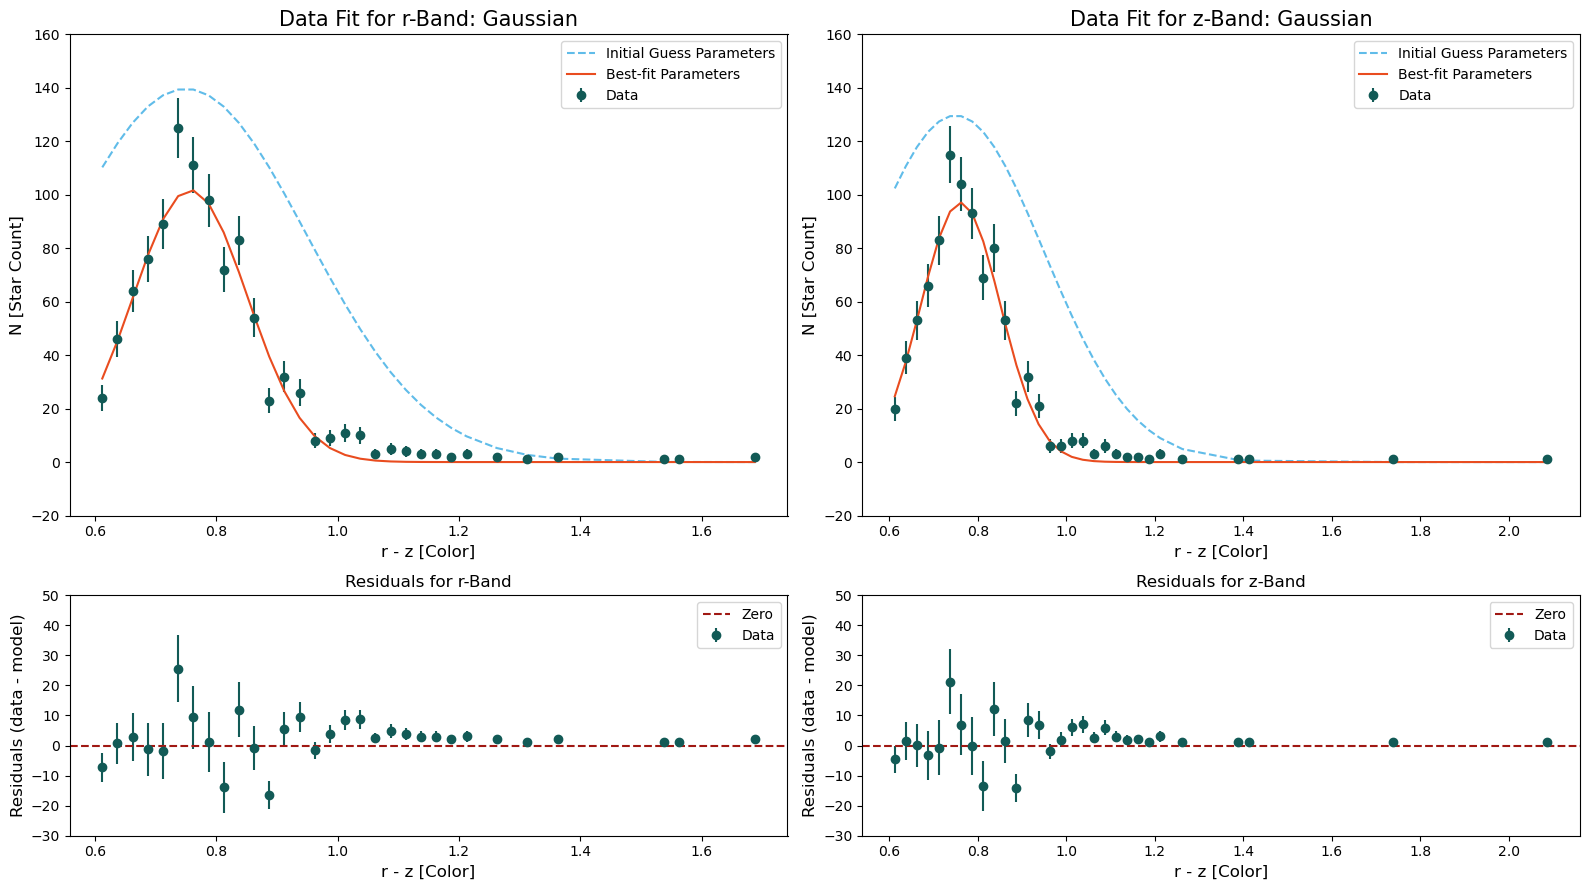

In [50]:
# Create figure with total height = 6 + 3 = 9, width = 16
fig = plt.figure(figsize=(16, 9))
gs = gridspec.GridSpec(2, 2, height_ratios=[6, 3])  # Top taller than bottom

# === Top-left: r-band data fit ===
ax1 = fig.add_subplot(gs[0, 0])
ax1.errorbar(bin_centers_m1, hist_counts_m1, yerr=np.sqrt(hist_counts_m1), fmt='o', color = '#125A56', marker = 'o', label='Data') 
ax1.plot(bin_centers_m1, cgauss(bin_centers_m1, *initial_guess_3), '#60BCE9', linestyle = '--', label='Initial Guess Parameters')
ax1.plot(bin_centers_m1, cgauss(bin_centers_m1, *par_1), '#E94C1F', label='Best-fit Parameters')
ax1.set_ylim(-20, 160)
ax1.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax1.set_ylabel("N [Star Count]", fontsize = 12)
ax1.set_title("Data Fit for r-Band: Gaussian", fontsize = 15)
ax1.legend(loc='best')

# === Top-right: z-band data fit ===
ax2 = fig.add_subplot(gs[0, 1])
ax2.errorbar(bin_centers_m1z, hist_counts_m1z, yerr=np.sqrt(hist_counts_m1z), fmt='o', color = '#125A56', marker = 'o', label='Data') 
ax2.plot(bin_centers_m1z, cgauss(bin_centers_m1z, *initial_guess_4), '#60BCE9', linestyle = '--', label='Initial Guess Parameters')
ax2.plot(bin_centers_m1z, cgauss(bin_centers_m1z, *par_1z), '#E94C1F', label='Best-fit Parameters')
ax2.set_ylim(-20, 160)
ax2.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax2.set_ylabel("N [Star Count]", fontsize = 12) 
ax2.set_title("Data Fit for z-Band: Gaussian", fontsize = 15)
ax2.legend(loc='best')

# === Bottom-left: residuals for r-band ===
ax3 = fig.add_subplot(gs[1, 0])
ax3.errorbar(bin_centers_m1, residuals_1, yerr=np.sqrt(hist_counts_m1), fmt='o', color = '#125A56', marker = 'o', label='Data')
ax3.axhline(0, color='#A01813', linestyle='--', label='Zero')
ax3.set_ylim(-30, 50)
ax3.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax3.set_ylabel("Residuals (data - model)", fontsize = 12)
ax3.set_title("Residuals for r-Band", fontsize = 12)
ax3.legend(loc='best')

# === Bottom-right: residuals for z-band ===
ax4 = fig.add_subplot(gs[1, 1])
ax4.errorbar(bin_centers_m1z, residuals_1z, yerr=np.sqrt(hist_counts_m1z), fmt='o', color = '#125A56', marker = 'o', label='Data')
ax4.axhline(0, color='#A01813', linestyle='--', label='Zero')
ax4.set_ylim(-30, 50)
ax4.set_xlabel(f"{color_band_1} - {color_band_2} [Color]", fontsize = 12)
ax4.set_ylabel("Residuals (data - model)", fontsize = 12)
ax4.set_title("Residuals for z-Band", fontsize = 12)
ax4.legend(loc='best')

plt.tight_layout()
plt.savefig('figures/rz_cgauss_sub4')
plt.show()

In [51]:
# Printing the results of the magnitude fit
print(
    f"{magnitude_band}_rc = {par_0[2]} ± {np.sqrt(cov_0[2, 2])}, "
    f"sigma_rc = {par_0[4]} ± {np.sqrt(cov_0[4, 4])}, "
    f"A_{magnitude_band} = {par_0[2] - clumpmag0_r} ± {np.sqrt(cov_0[2, 2])}"
     )
# Printing the results of the color fit
magnitude_rc = par_0[2]
A_r = magnitude_rc - clumpmag0_r
color_rc = np.nanmedian(clump_candidates[:, c1_col_index] - clump_candidates[:, c2_col_index])
color_rc = par_1[1]
E_color = color_rc - (red_clump["clump-" + color_band_1] - red_clump["clump-" + color_band_2]) # include error
E_color_err = np.sqrt(cov_1[1,1])
tot2sel = A_r / E_color
print(f"E({color_band_1}-{color_band_2}) = {E_color} ± {E_color_err} , " 
      f"Tot/Sel = {tot2sel}"
     )

r_rc = 15.855734246157423 ± 0.044045519345405466, sigma_rc = 0.5486165259026593 ± 0.05250105980651918, A_r = 0.779813944552858 ± 0.044045519345405466
E(r-z) = 0.3446186301058546 ± 0.005923775707116403 , Tot/Sel = 2.26283165339415


In [52]:
# Printing the results of the magnitude fit
print(
    f"{color_band_2}_rc = {par_0z[2]} ± {np.sqrt(cov_0z[2, 2])}, "
    f"sigma_rc = {par_0z[4]} ± {np.sqrt(cov_0z[4, 4])}, "
    f"A_{color_band_2} = {par_0z[2] - clumpmag0_z} ± {np.sqrt(cov_0z[2, 2])}"
)
# Printing the results of the color fit
magnitude_rc_z = par_0z[2]
A_z = magnitude_rc_z - clumpmag0_z
color_rc_z = np.nanmedian(clump_candidates_z[:, c1_col_index] - clump_candidates_z[:, c2_col_index])
color_rc_z = par_1z[1]
E_color_z = color_rc_z - (red_clump["clump-" + color_band_1] - red_clump["clump-" + color_band_2]) # include error
E_color_z_err = np.sqrt(cov_1z[1,1])
tot2sel_z = A_z / E_color_z
print(f"E({color_band_1}-{color_band_2})_{color_band_2} = {E_color_z} ± {E_color_z_err} , " 
      f"Tot/Sel = {tot2sel_z}"
     )

z_rc = 15.079085656946738 ± 0.040293617212654884, sigma_rc = 0.5010079077214341 ± 0.0493874821255483, A_z = 0.41610270566272867 ± 0.040293617212654884
E(r-z)_z = 0.3483878978222502 ± 0.005184894203272606 , Tot/Sel = 1.1943661311536917


In [53]:
initial_guess_2 = [10.74, 1.24, 15.89, 77.18, 0.62] # Initial guess for the curve fit from rcmodel results


par_2,cov_2 = spopt.curve_fit(rcmodel, bin_centers_m0, hist_counts_m0, p0 = initial_guess_2, sigma = np.sqrt(hist_counts_m0))
print(f"rcmodel Fit Results:\nAmplitude = {par_2[0]:.2f}\n  Slope = {par_2[1]:.2f}\n Magnitude of red clump = {par_2[2]:.2f}\n  Number of red clump stars = {par_2[3]:.2f}\n  Sigma = {par_2[4]:.2f}")

amplitude, slope, magnitude_giant, number_giant, sigma_giant = par_2

plt.figure(figsize=(8,6))
plt.tight_layout()

plt.errorbar(bin_centers_m0, hist_counts_m0, yerr = np.sqrt(hist_counts_m0), fmt = 'ko', label = 'Data') 

# Compute residuals
model_vals_0 = rcmodel(bin_centers_m0, *par_2)
residuals_0 = hist_counts_m0 - model_vals_0

plt.plot(bin_centers_m0, rcmodel(bin_centers_m0, *initial_guess_0), 'b--', label = 'OG Initial Guess Parameters')
plt.plot(bin_centers_m0, rcmodel(bin_centers_m0, *initial_guess_2), 'c-.', label = 'rcfit Guess Parameters')
plt.plot(bin_centers_m0, rcmodel(bin_centers_m0, *par_0), 'r.', label = 'OG Best-fit Parameters')
plt.plot(bin_centers_m0, rcmodel(bin_centers_m0, *par_2), 'm-', label = 'rcfit Model Results')

plt.xlabel(f"{magnitude_band} [Magnitude]")
plt.ylabel(f"N")
plt.title('Data Fit: Quadradic + Gaussian (Initial Guess 0 vs. Initial Guess 2)')

plt.legend(loc='best')
plt.show()

# Plot residuals
plt.figure(figsize = (8, 2))
plt.tight_layout()

plt.errorbar(bin_centers_m0, residuals_0, yerr = np.sqrt(hist_counts_m0), fmt = 'ko', label = 'Data')
plt.axhline(0, color ='gray', linestyle ='--', label = 'Zero')

plt.xlabel(f"{magnitude_band} [Magnitude]")
plt.ylabel('Residuals (data - model)')
plt.title('Residuals Plot')

plt.legend(loc = 'best')
plt.show()

print(
    f"{magnitude_band}_rc = {par_2[2]:6.3f} ± {np.sqrt(cov_2[2, 2]):5.3f}, "
    f"sigma_rc = {par_2[4]:6.3f} ± {np.sqrt(cov_2[4, 4]):5.3f}, "
    f"A_{magnitude_band} = {par_2[2] - clumpmag0:5.3f} ± {np.sqrt(cov_2[2, 2]):5.3f}"
)

NameError: name 'rcmodel' is not defined

In [ ]:
print('par 0:',par_0)
print('par 2:',par_2)

In [ ]:
# Initial guess for Gaussian parameters: amplitude, mean, sigma
initial_guess_3 = [26.78, 0.75, 0.09]

par_3, cov_3 = spopt.curve_fit(cgauss, bin_centers_m1, hist_counts_m1, p0 = initial_guess_3, sigma=np.sqrt(hist_counts_m1))
print(f"cgauss Model Fit Results:\nAmplitude = {par_3[0]:.2f}\n  Mean = {par_3[1]:.2f}\n Sigma = {par_3[2]:.2f}")

amplitude, mean, sigma = par_3

plt.figure(figsize=(8,6))
plt.tight_layout()

plt.errorbar(bin_centers_m1, hist_counts_m1, yerr = np.sqrt(hist_counts_m1), fmt = 'ko', label = 'Data')

# Compute residuals
model_vals_1 = cgauss(bin_centers_m1, *par_3)
residuals_1 = hist_counts_m1 - model_vals_1

plt.plot(bin_centers_m1, cgauss(bin_centers_m1, *initial_guess_1), 'b-.', label = 'OG Initial Guess Parameters')
plt.plot(bin_centers_m1, cgauss(bin_centers_m1, *initial_guess_3), 'c--', label = 'cgauss Guess Parameters')
plt.plot(bin_centers_m1, cgauss(bin_centers_m1, *par_1), 'r.', label = 'OG Best-fit Parameters')
plt.plot(bin_centers_m1, cgauss(bin_centers_m1, *par_3), 'm-', label = 'cgauss model Results')

plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel(f"N")
plt.title('Data Fit: Gaussian (Initial Guess 1 vs. Initial Guess 3)')

plt.legend(loc='best')
plt.show()

# Plot residuals
plt.figure(figsize=(8, 2))
plt.tight_layout()

plt.errorbar(bin_centers_m1, residuals_1, yerr=np.sqrt(hist_counts_m1), fmt='ko', label = 'Data')
plt.axhline(0, color='gray', linestyle='--', label = 'Zero')

plt.xlabel(f"{color_band_1} - {color_band_2} [Color]")
plt.ylabel('Residuals (data - model)')
plt.title('Residuals Plot')

plt.legend(loc = 'best')
plt.show()

print(rf"({color_band_1}-{color_band_2}) = {par_3[1]:.3f} ± {np.sqrt(cov_3[1,1]):.3f}, σ_({color_band_1}-{color_band_2}) = {par_3[2]:.3f} ± {np.sqrt(cov_3[2,2]):.3f}")

In [ ]:
print('par 1:',par_1)
print('par 3:',par_3)

In [ ]:
print(cov_0)
print(cov_0[2, 2])

print(cov_1)
print(cov_1[2, 2])